In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from scipy import stats
singlecol = 3.5
plt.rcParams.update({'font.size': 16})
#plt.rcParams.update({'font.sans-serif': 'Helvetica'})
plt.rcParams.update({'lines.linewidth':1.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':7})
plt.rcParams.update({'savefig.dpi':200})
plt.rcParams.update({'legend.fontsize': 12})

In [2]:
# Separate the cfg file into section
# Load Each section one by one
def load_cfg(filename):
    try:
        with open(filename, 'r') as file:
            lines = file.readlines()[4:-5]  # Read from the 5th line onwards 
        
        # Split each line into separate numbers
        numbers = []
        for line in lines:
            line_numbers = [float(num) for num in line.split()]  # Assuming numbers are floats
            numbers.append(line_numbers)
        
        # Convert the list of lists into a NumPy array
        return np.array(numbers)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")


In [3]:
import numpy as np

def load_multi_section_cfg(filename):
    energies = []
    atom_data_list = []
    stress_data_list = []
    
    try:
        with open(filename, 'r', encoding="utf-8", errors="ignore") as file:
            content = file.read()
            
            # Split the content into sections
            cfg_sections = content.split('BEGIN_CFG')[1:]  # Skip the first empty split
            
            for section in cfg_sections:
                lines = section.strip().split('\n')
                
                # Extract Size
                size = int(next(line.strip() for line in lines if line.strip().isdigit()))
                
                # Extract AtomData
                atom_data_start = next(i for i, line in enumerate(lines) if line.strip().startswith('AtomData:'))
                atom_data = np.array([list(map(float, line.split()[1:])) for line in lines[atom_data_start+1:atom_data_start+size+1]])
                atom_data_list.append(atom_data)
                
                # Extract Energy
                energy_line_index = next(i for i, line in enumerate(lines) if line.strip().startswith('Energy'))
                energy = float(lines[energy_line_index+1].split()[0])
                energies.append(energy)
                
                # Extract PlusStress
                stress_line = next(line for line in lines if line.strip().startswith('PlusStress:'))
                stress = np.array(list(map(float, lines[lines.index(stress_line) + 1].split())))
                stress_data_list.append(stress)
        
        return np.array(energies),atom_data_list, np.array(stress_data_list)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")
        return None, None, None

In [4]:
import numpy as np

def load_multi_section_cfg_grade(filename):
    energies = []
    supercell_list = []
    atom_data_list = []
    stress_data_list = []
    grade_data_list = []
    
    try:
        with open(filename, 'r') as file:
            content = file.read()
            
            # Split the content into sections
            cfg_sections = content.split('BEGIN_CFG')[1:]  # Skip the first empty split
            
            for section in cfg_sections:
                lines = section.strip().split('\n')
                
                # Extract Size
                size = int(next(line.strip() for line in lines if line.strip().isdigit()))

                # Extract Supercell
                supercell_start = next(i for i, line in enumerate(lines) if line.strip().startswith('Supercell'))
                supercell = np.array([list(map(float, line.split()[:])) for line in lines[supercell_start+1:supercell_start+3+1]])
                supercell_list.append(supercell)
                
                # Extract AtomData
                atom_data_start = next(i for i, line in enumerate(lines) if line.strip().startswith('AtomData:'))
                atom_data = np.array([list(map(float, line.split())) for line in lines[atom_data_start+1:atom_data_start+size+1]])
                atom_data_list.append(atom_data)
                
                # Extract Energy
                energy_line_index = next(i for i, line in enumerate(lines) if line.strip().startswith('Energy'))
                energy = float(lines[energy_line_index+1].split()[0])
                energies.append(energy)
                
                # Extract PlusStress
                stress_line = next(line for line in lines if line.strip().startswith('PlusStress:'))
                stress = np.array(list(map(float, lines[lines.index(stress_line) + 1].split())))
                stress_data_list.append(stress)
        
                # Extract PlusStress
                grade_line = next(line for line in lines if line.strip().startswith('Feature   MV_grade'))
                grade = float(grade_line.split()[-1])
                grade_data_list.append(grade)
        
        return np.array(energies), np.array(supercell_list), atom_data_list, np.array(stress_data_list), np.array(grade_data_list)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")
        return None, None, None

In [5]:
import numpy as np

def load_multi_section_cfg_no_grade(filename):
    energies = []
    supercell_list = []
    atom_data_list = []
    stress_data_list = []
    grade_data_list = []
    
    try:
        with open(filename, 'r') as file:
            content = file.read()
            
            # Split the content into sections
            cfg_sections = content.split('BEGIN_CFG')[1:]  # Skip the first empty split
            
            for section in cfg_sections:
                lines = section.strip().split('\n')
                
                # Extract Size
                size = int(next(line.strip() for line in lines if line.strip().isdigit()))

                # Extract Supercell
                supercell_start = next(i for i, line in enumerate(lines) if line.strip().startswith('Supercell'))
                supercell = np.array([list(map(float, line.split()[:])) for line in lines[supercell_start+1:supercell_start+3+1]])
                supercell_list.append(supercell)
                
                # Extract AtomData
                atom_data_start = next(i for i, line in enumerate(lines) if line.strip().startswith('AtomData:'))
                atom_data = np.array([list(map(float, line.split())) for line in lines[atom_data_start+1:atom_data_start+size+1]])
                atom_data_list.append(atom_data)
                
                # Extract Energy
                energy_line_index = next(i for i, line in enumerate(lines) if line.strip().startswith('Energy'))
                energy = float(lines[energy_line_index+1].split()[0])
                energies.append(energy)
                
                # Extract PlusStress
                stress_line = next(line for line in lines if line.strip().startswith('PlusStress:'))
                stress = np.array(list(map(float, lines[lines.index(stress_line) + 1].split())))
                stress_data_list.append(stress)
        
        return np.array(energies), np.array(supercell_list), atom_data_list, np.array(stress_data_list)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")
        return None, None, None

In [6]:
def calculate_rmse(actual, predicted):
    mse = np.mean((actual - predicted) ** 2)
    rmse = np.sqrt(mse)
    return rmse

In [7]:
def flatten(lst):
    flattened = []
    for item in lst:
        if isinstance(item, list):
            flattened.extend(flatten(item))
        else:
            flattened.append(item)
    return flattened

In [8]:
def plot_validation_fix(activeset, traing_set):
    E_act, F_act, S_act = load_multi_section_cfg(activeset)
    E_train, F_train, S_train = load_multi_section_cfg(traing_set)
    
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19,5))
    plt.subplots_adjust(wspace=0.35)
    bin_edges = np.arange(E_train.min(), 0,100)
    
    ax1.hist(E_train, edgecolor='black',bins=bin_edges, alpha=0.4, label='training set')
    ax1.set_ylabel('Counts')
    ax12 = ax1.twinx()
    ax12.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.4, label='active set', color='tab:orange')
    
    ax12.tick_params(axis='y', labelcolor='tab:orange')

    ax1.set_xlabel('Energy')
    ax1.set_ylabel('Counts')
    
    F_act = np.array(F_act, dtype=object)
    Na_count_act = []
    atom_count_act = []
    for i in range(len(E_act)):
        Na_count_act.append(np.sum(F_act[:][i] == 4))
        atom_count_act.append(F_act[i].shape[0])
    
    Na_count_act = np.array(Na_count_act)
    atom_count_act = np.array(atom_count_act)
    E_act = np.array(E_act)
    
    F_train = np.array(F_train, dtype=object)
    Na_count_train = []
    atom_count_train = []
    for i in range(len(E_train)):
        Na_count_train.append(np.sum(F_train[:][i] == 4))
        atom_count_train.append(F_train[i].shape[0])
    
    Na_count_train = np.array(Na_count_train)
    atom_count_train = np.array(atom_count_train)
    E_train = np.array(E_train)
    
    bin_edges = np.arange(min(Na_count_train), max(Na_count_train),1)
    ax2.hist(Na_count_train, edgecolor='black',bins=bin_edges, alpha=0.4, label='Training set')
    ax22 = ax2.twinx()
    ax22.hist(Na_count_act, edgecolor='black',bins=bin_edges, alpha=0.4, label='Active set', color='tab:orange')
    
    ax22.tick_params(axis='y', labelcolor='tab:orange')
    
    ax2.set_xlabel('Number of Na per structure')
    ax2.set_ylabel('Counts')
    
    
    ax3.scatter(E_train, Na_count_train, alpha=0.5, label=f'Train {E_train.shape[0]} cfgs')
    ax3.scatter(E_act, Na_count_act, alpha=0.3, label=f'Active {E_act.shape[0]} cfgs')

    ax3.legend(loc='upper right')
    ax3.set_ylabel('Number of Na per structure')
    ax3.set_xlabel('Energy')
    plt.title(filename_2)
###################################
    ax12.set_ylim(0,120)
    ax1.set_ylim(0,900)
    ax22.set_ylim(0,80)
    ax2.set_ylim(0,800)
    ax3.set_xlim(-4200,1000)
    #plt.savefig(traing_set+'.jpg', bbox_inches='tight')

In [9]:
def plot_validation(traing_set, activeset,num):
    
    E_act, F_act, S_act = load_multi_section_cfg(activeset)
    E_train, F_train, S_train = load_multi_section_cfg(traing_set)
    
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19,5))
    plt.subplots_adjust(wspace=0.35)
    bin_edges = np.arange(E_train.min(), E_train.max(),100)
    
    ax1.hist(E_train, edgecolor='black',bins=bin_edges, alpha=0.4, label='training set')
    ax1.set_ylabel('Counts')
    ax12 = ax1.twinx()
    ax12.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.4, label='active set', color='tab:orange')
    
    ax12.tick_params(axis='y', labelcolor='tab:orange')

    ax1.set_xlabel('Energy')
    ax1.set_ylabel('Counts')
    
    F_act = np.array(F_act, dtype=object)
    Na_count_act = []
    atom_count_act = []
    for i in range(len(E_act)):
        Na_count_act.append(np.sum(F_act[:][i] == 4))
        atom_count_act.append(F_act[i].shape[0])
    
    Na_count_act = np.array(Na_count_act)
    atom_count_act = np.array(atom_count_act)
    E_act = np.array(E_act)
    
    F_train = np.array(F_train, dtype=object)
    Na_count_train = []
    atom_count_train = []
    for i in range(len(E_train)):
        Na_count_train.append(np.sum(F_train[:][i] == 4))
        atom_count_train.append(F_train[i].shape[0])
    
    Na_count_train = np.array(Na_count_train)
    atom_count_train = np.array(atom_count_train)
    E_train = np.array(E_train)
    
    bin_edges = np.arange(min(Na_count_train), max(Na_count_train),1)
    ax2.hist(Na_count_train, edgecolor='black',bins=bin_edges, alpha=0.4, label='Training set')
    ax22 = ax2.twinx()
    ax22.hist(Na_count_act, edgecolor='black',bins=bin_edges, alpha=0.4, label='Active set', color='tab:orange')
    num=num
    ax22.hist(Na_count_train[-num:], edgecolor='black',bins=bin_edges, alpha=0.4, label='new', color='r')
    
    ax22.tick_params(axis='y', labelcolor='tab:orange')
    
    ax2.set_xlabel('Number of Na per structure')
    ax2.set_ylabel('Counts')
    
    
    ax3.scatter(E_train, Na_count_train, alpha=0.3, label=f'Train {E_train.shape[0]} cfgs')
    ax3.scatter(E_act, Na_count_act, alpha=0.5, label=f'Active {E_act.shape[0]} cfgs')
    num=num
    ax3.scatter(E_train[-num:], Na_count_train[-num:], alpha=0.8, label=f'new {num} cfgs', color='r')

    ax3.legend()
    ax3.set_ylabel('Number of Na per structure')
    ax3.set_xlabel('Energy')
    plt.title(traing_set)
    plt.savefig(traing_set+'.jpg', bbox_inches='tight')

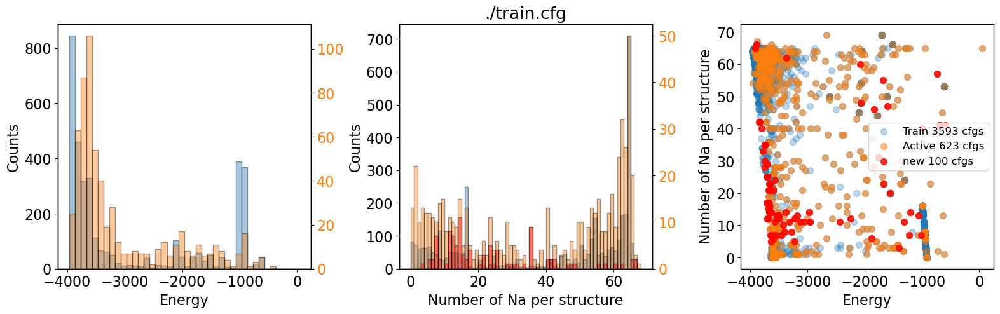

In [10]:
plot_validation('./train.cfg','./curr.almtp',100)

In [13]:
plot_validation('./../../Projects/MTP_AIMD/test_12_cfg/train.cfg','./Projects/MTP_AIMD/test_12_cfg/curr.almtp',100)

Error: File './Projects/MTP_AIMD/test_12_cfg/curr.almtp' not found.


TypeError: cannot unpack non-iterable NoneType object

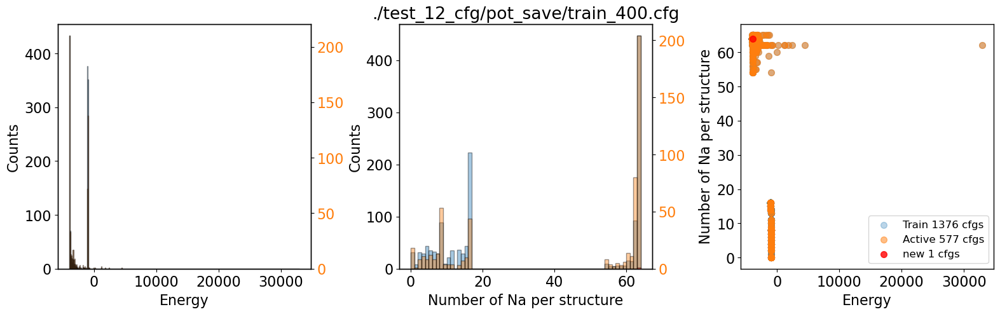

In [14]:
plot_validation('./test_12_cfg/pot_save/train_400.cfg','./test_12_cfg/pot_save/curr_400.almtp',1)

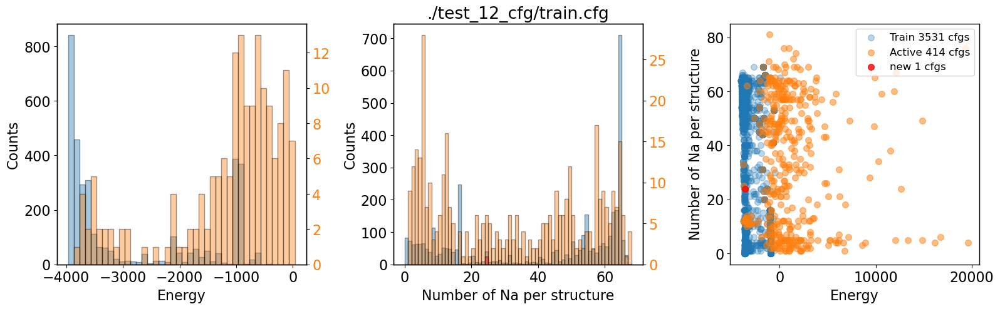

In [15]:
plot_validation('./test_12_cfg/train.cfg','./test_12_cfg/vasp.cfg',1)

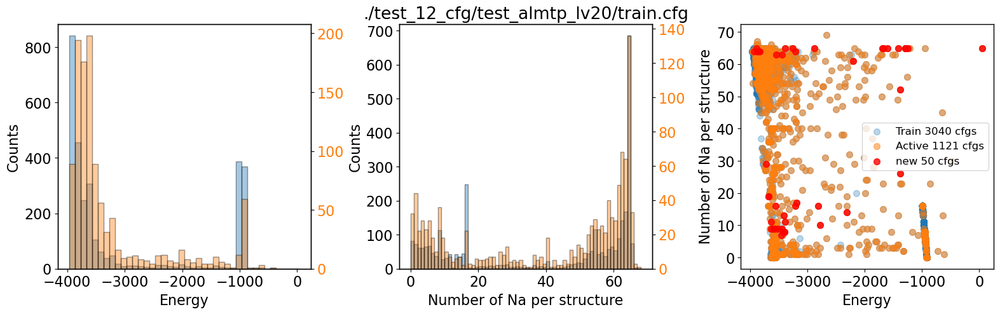

In [11]:
plot_validation('./test_12_cfg/test_almtp_lv20/train.cfg','./test_12_cfg/test_almtp_lv20/curr.almtp',50)

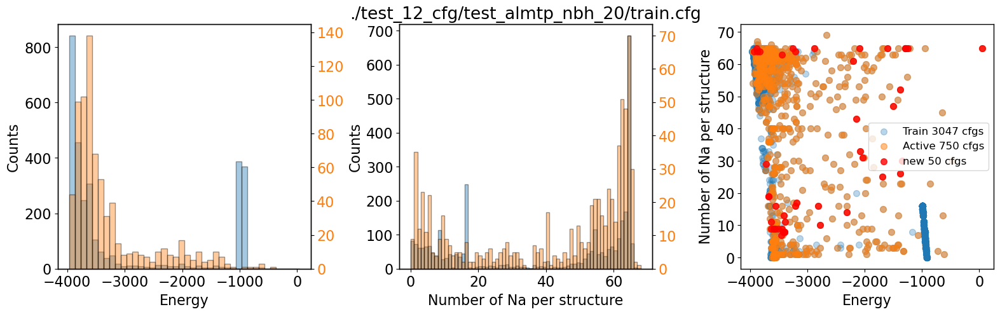

In [11]:
plot_validation('./test_12_cfg/test_almtp_nbh_20/train.cfg','./test_12_cfg/test_almtp_nbh_20/curr.almtp',50)

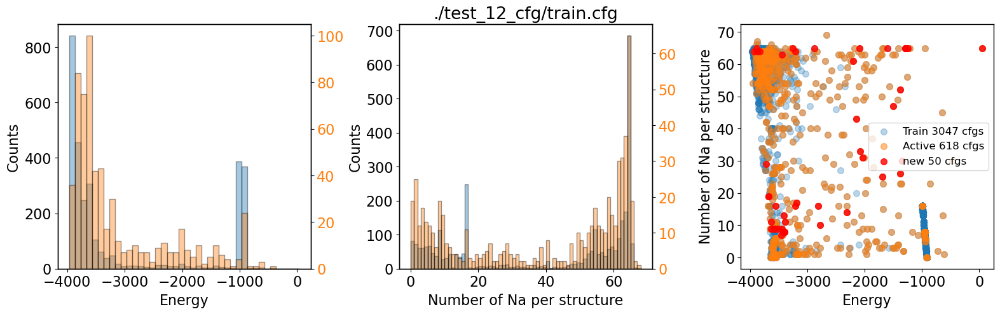

In [11]:
plot_validation('./test_12_cfg/train.cfg','./test_12_cfg/test_lammps/curr.almtp',50)

### test training set

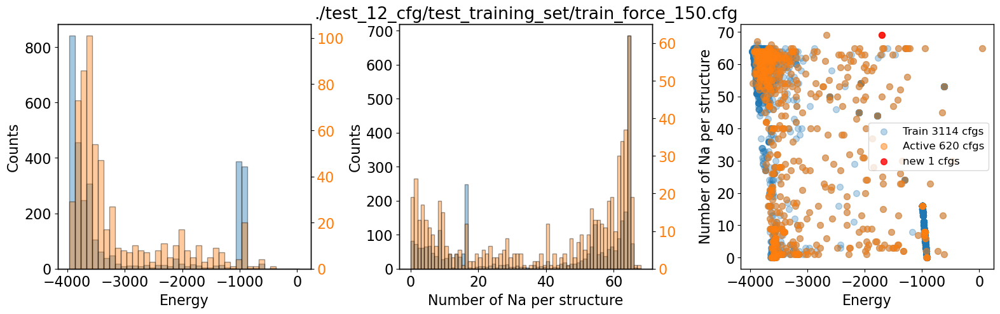

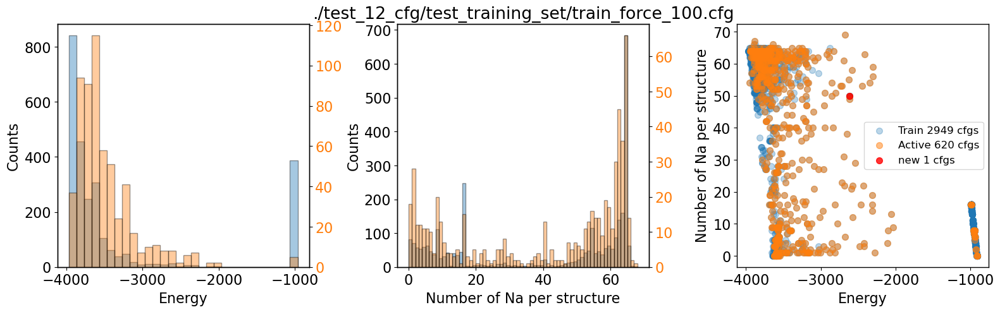

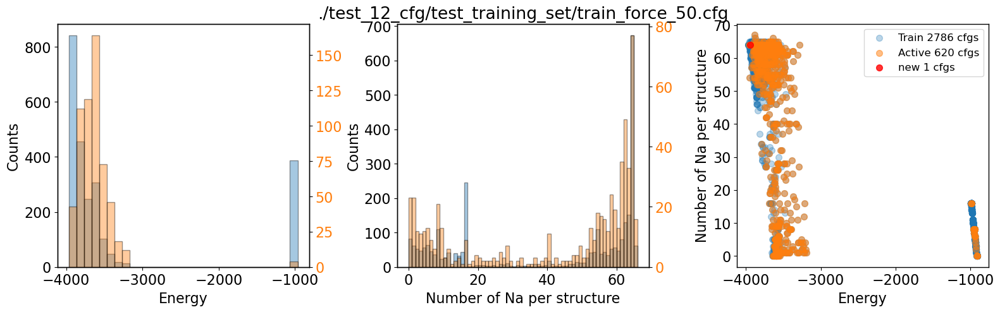

In [13]:
plot_validation('./test_12_cfg/test_training_set/train_force_150.cfg','./test_12_cfg/test_training_set/curr_cfg_force_150.almtp',1)
plot_validation('./test_12_cfg/test_training_set/train_force_100.cfg','./test_12_cfg/test_training_set/curr_cfg_force_100.almtp',1)
plot_validation('./test_12_cfg/test_training_set/train_force_50.cfg','./test_12_cfg/test_training_set/curr_cfg_force_50.almtp',1)

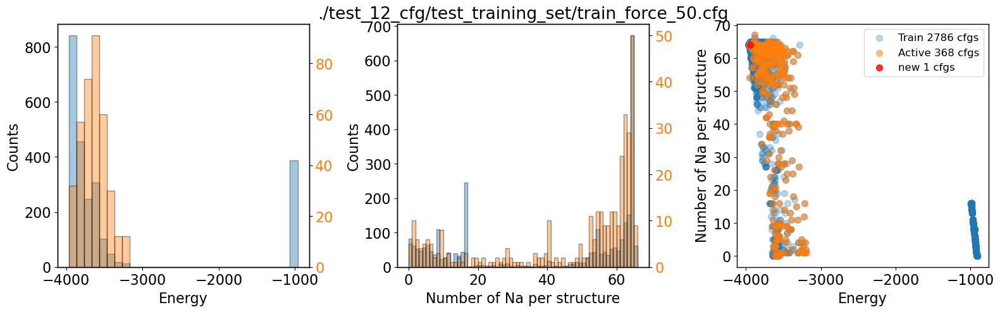

In [13]:
plot_validation('./test_12_cfg/test_training_set/train_force_50.cfg','./test_12_cfg/test_training_set/curr_nbh_force_50.almtp',1)

In [ ]:
plot_validation('./test_12_cfg/test_training_set/train_force_50.cfg','./test_12_cfg/test_training_set/curr_nbh_force_50.almtp',1)

/tmp/ipykernel_30731/2986484191.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19,5))


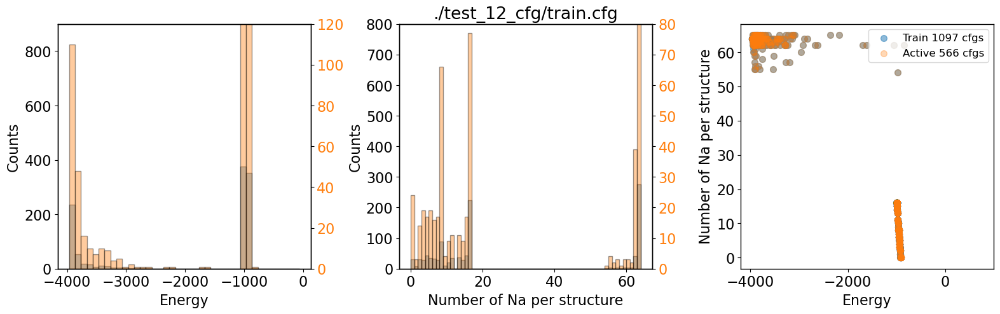

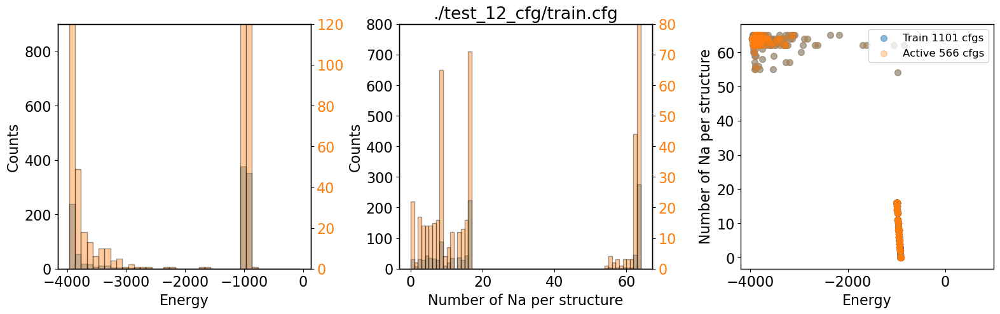

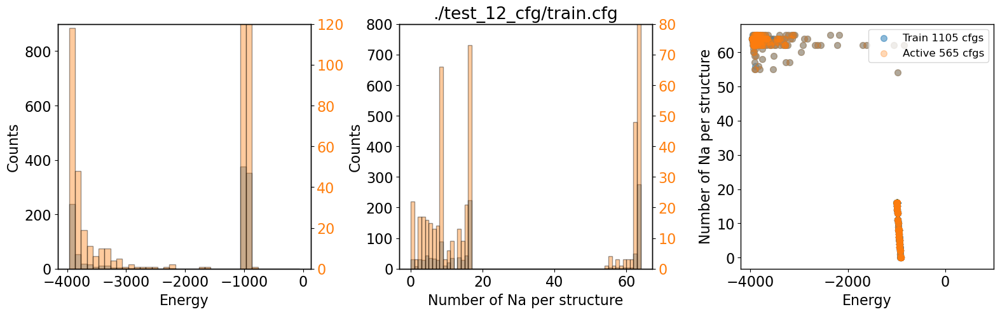

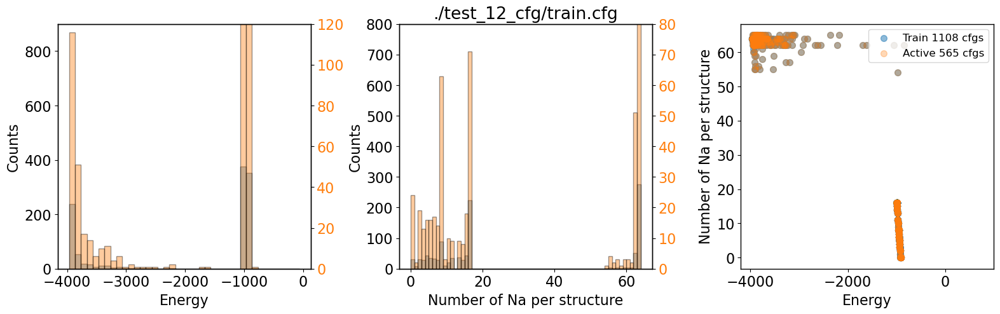

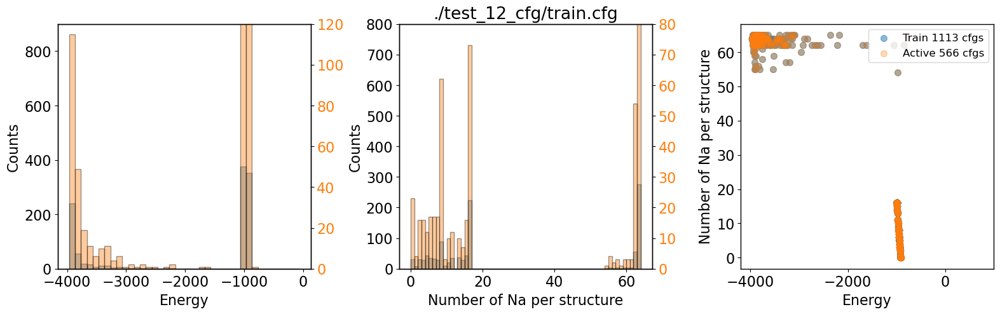

...

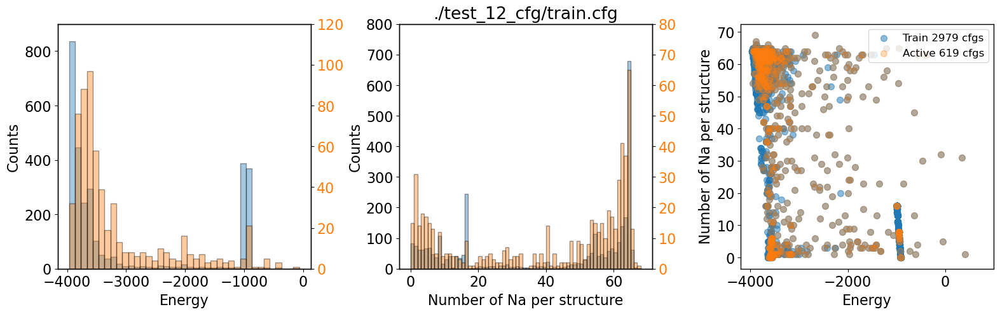

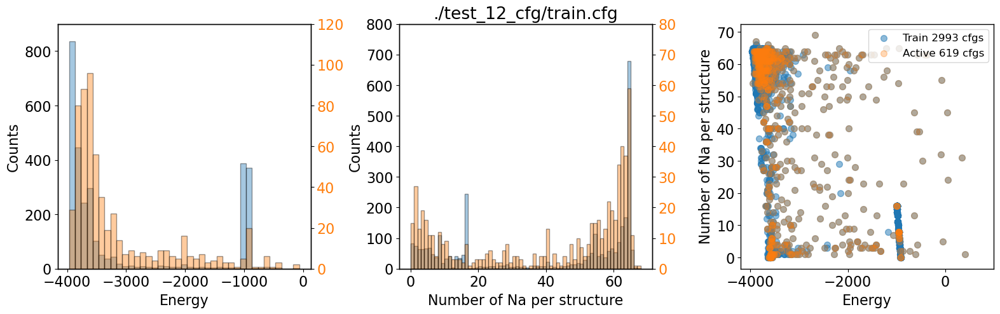

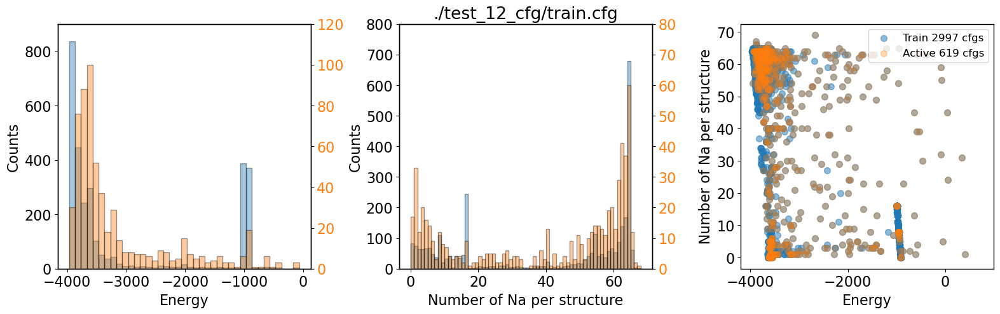

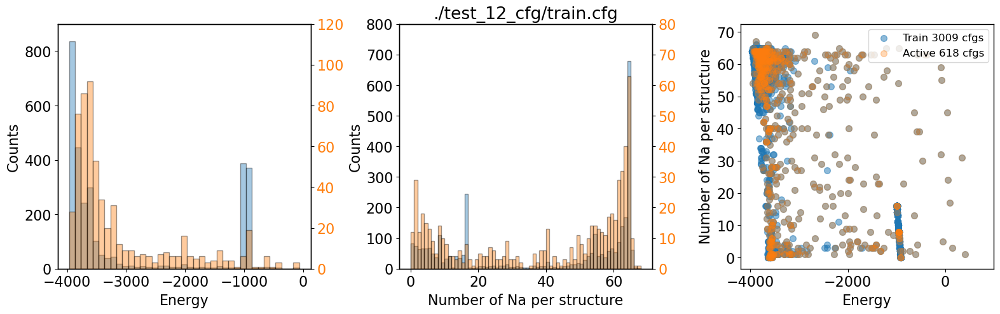

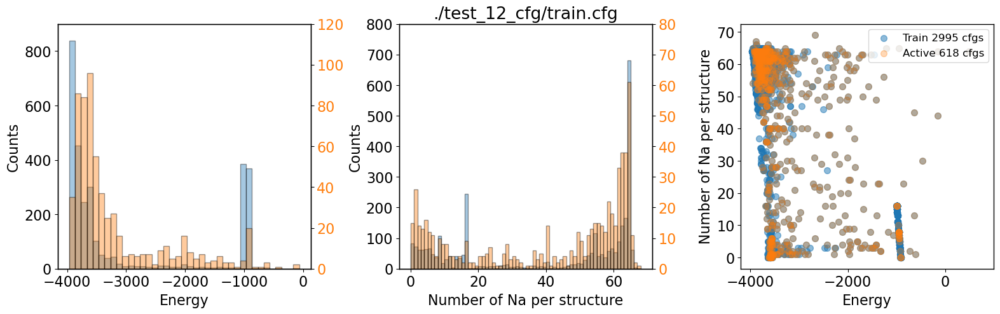

In [96]:
for i in range(350,499):
    active_set = f'./test_12_cfg/pot_save/curr_{i+1}.almtp'
    train_set = f'./test_12_cfg/pot_save/train_{i+1}.cfg'
    plot_validation_fix(active_set, train_set)

In [15]:
np.arange(-1.5,-1.3,0.02)


array([-1.5 , -1.48, -1.46, -1.44, -1.42, -1.4 , -1.38, -1.36, -1.34,
       -1.32])

In [98]:
#import imageio

filenames = os.listdir('./test_12_cfg/pot_save/picture')
import re

# Define a custom key function to extract the number from each filename
def extract_number(filename):
    # Use regular expression to find the number in the filename
    match = re.search(r'\d+', filename)
    if match:
        return int(match.group())
    else:
        return float('inf')  # Return infinity if no number found

# Sort the list of filenames using the custom key function
sorted_file_names = sorted(filenames, key=extract_number)

print(sorted_file_names)

['train_351.cfg.jpg', 'train_352.cfg.jpg', 'train_353.cfg.jpg', 'train_354.cfg.jpg', 'train_355.cfg.jpg', 'train_356.cfg.jpg', 'train_357.cfg.jpg', 'train_358.cfg.jpg', 'train_359.cfg.jpg', 'train_360.cfg.jpg', 'train_361.cfg.jpg', 'train_362.cfg.jpg', 'train_363.cfg.jpg', 'train_364.cfg.jpg', 'train_365.cfg.jpg', 'train_366.cfg.jpg', 'train_367.cfg.jpg', 'train_368.cfg.jpg', 'train_369.cfg.jpg', 'train_370.cfg.jpg', 'train_371.cfg.jpg', 'train_372.cfg.jpg', 'train_373.cfg.jpg', 'train_374.cfg.jpg', 'train_375.cfg.jpg', 'train_376.cfg.jpg', 'train_377.cfg.jpg', 'train_378.cfg.jpg', 'train_379.cfg.jpg', 'train_380.cfg.jpg', 'train_381.cfg.jpg', 'train_382.cfg.jpg', 'train_383.cfg.jpg', 'train_384.cfg.jpg', 'train_385.cfg.jpg', 'train_386.cfg.jpg', 'train_387.cfg.jpg', 'train_388.cfg.jpg', 'train_389.cfg.jpg', 'train_390.cfg.jpg', 'train_391.cfg.jpg', 'train_392.cfg.jpg', 'train_393.cfg.jpg', 'train_394.cfg.jpg', 'train_395.cfg.jpg', 'train_396.cfg.jpg', 'train_397.cfg.jpg', 'train_398.c

In [105]:
with imageio.get_writer('train_evolution_spare.gif', mode='I', duration=2) as writer:    # inputs: filename, frame per second
    for i in range(350,500,5):
        image = imageio.imread('./test_12_cfg/pot_save/picture/' + f'train_{i+1}.cfg.jpg')                         # load the image file
        writer.append_data(image)                                # append the image file
print('Gif saved!\n')

/tmp/ipykernel_30731/1136094234.py:3: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread('./test_12_cfg/pot_save/picture/' + f'train_{i+1}.cfg.jpg')                         # load the image file


Gif saved!



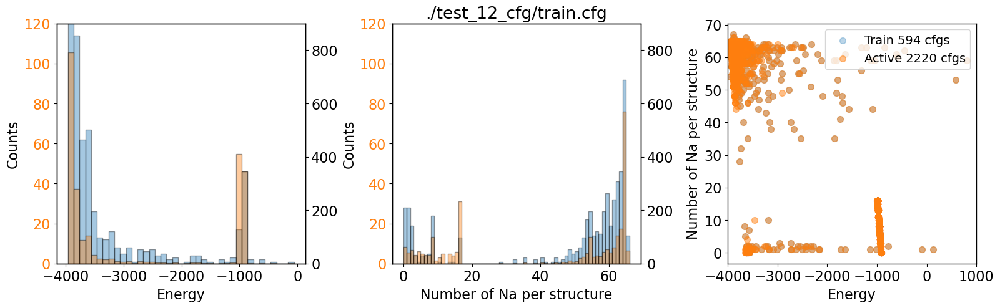

In [87]:
plot_validation_fix('./test_12_cfg/pot_save/curr_450.almtp','./test_12_cfg/pot_save/train_450.cfg')

Text(0.5, 1.0, './test_12_cfg/train.cfg')

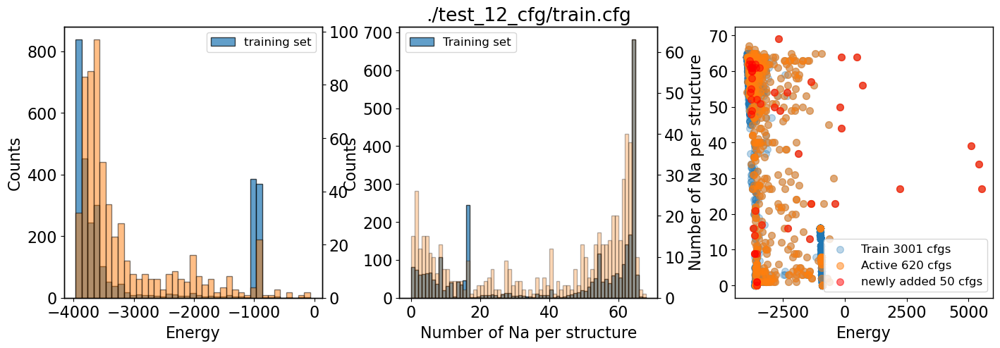

In [51]:
filename_1 = './test_12_cfg/curr.almtp'
E_act, F_act, S_act = load_multi_section_cfg(filename_1)

filename_2 = './test_12_cfg/train.cfg'
E_train, F_train, S_train = load_multi_section_cfg(filename_2)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17,5))
plt.subplots_adjust(wspace=0.3)

bin_edges = np.arange(E_train.min(), 0,100)
ax1.hist(E_train, edgecolor='black',bins=bin_edges, alpha=0.7, label='training set')
ax1.set_ylabel('Counts')
ax12 = ax1.twinx()
ax12.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.5, label='active set', color='tab:orange')
#ax12.spines['right'].set_position(('outward', 10))
#ax12.tick_params(axis='y', labelcolor='tab:orange')
ax1.legend()
ax1.set_xlabel('Energy')
ax1.set_ylabel('Counts')

F_act = np.array(F_act, dtype=object)
Na_count_act = []
atom_count_act = []
for i in range(len(E_act)):
    Na_count_act.append(np.sum(F_act[:][i] == 4))
    atom_count_act.append(F_act[i].shape[0])

Na_count_act = np.array(Na_count_act)
atom_count_act = np.array(atom_count_act)
E_act = np.array(E_act)

F_train = np.array(F_train, dtype=object)
Na_count_train = []
atom_count_train = []
for i in range(len(E_train)):
    Na_count_train.append(np.sum(F_train[:][i] == 4))
    atom_count_train.append(F_train[i].shape[0])

Na_count_train = np.array(Na_count_train)
atom_count_train = np.array(atom_count_train)
E_train = np.array(E_train)

condition_1 = (atom_count_train > 400) & (E_train < -3000)
condition_2 = atom_count_train < 200
reasonable_indices_1 = np.where(condition_1)
reasonable_indices_2 = np.where(condition_2)
reasonable_indices = np.concatenate((reasonable_indices_1[0],reasonable_indices_2[0]))

bin_edges = np.arange(min(Na_count_train), max(Na_count_train),1)
#ax2.hist(Na_count, edgecolor='black',bins=bin_edges, alpha=0.7)
ax2.hist(Na_count_train, edgecolor='black',bins=bin_edges, alpha=0.7, label='Training set')

ax22 = ax2.twinx()
#ax22.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.5, label='active set', color='tab:orange')
ax22.hist(Na_count_act, edgecolor='black',bins=bin_edges, alpha=0.3, label='Active set', color='tab:orange')
ax2.legend()
ax2.set_xlabel('Number of Na per structure')
ax2.set_ylabel('Counts')


ax3.scatter(E_train, Na_count_train, alpha=0.3, label=f'Train {E_train.shape[0]} cfgs')
ax3.scatter(E_act, Na_count_act, alpha=0.5, label=f'Active {E_act.shape[0]} cfgs')
num=50
ax3.scatter(E_train[-num:], Na_count_train[-num:], alpha=0.5, label=f'newly added {num} cfgs', color='r')
#ax3.scatter(E_act[reasonable_indices], Na_count[reasonable_indices], alpha=0.3, color='red', label=f'Reasonable {reasonable_indices.shape[0]} cfgs')
ax3.legend()
ax3.set_ylabel('Number of Na per structure')
ax3.set_xlabel('Energy')

plt.title(filename_2)

Text(0.5, 1.0, './test_12_cfg/pot_save/train_450.cfg')

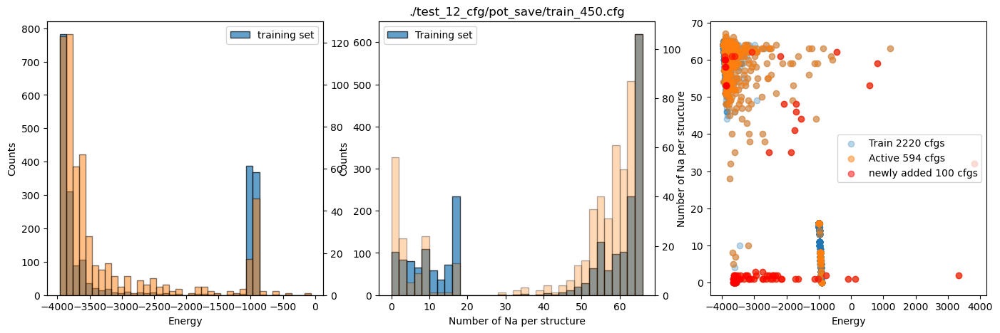

In [9]:
filename_1 = './test_12_cfg/pot_save/curr_450.almtp'
E_act, F_act, S_act = load_multi_section_cfg(filename_1)

filename_2 = './test_12_cfg/pot_save/train_450.cfg'
E_train, F_train, S_train = load_multi_section_cfg(filename_2)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17,5))

bin_edges = np.arange(E_train.min(), 0,100)
ax1.hist(E_train, edgecolor='black',bins=bin_edges, alpha=0.7, label='training set')
ax1.set_ylabel('Counts')
ax12 = ax1.twinx()
ax12.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.5, label='active set', color='tab:orange')
#ax12.spines['right'].set_position(('outward', 10))
#ax12.tick_params(axis='y', labelcolor='tab:orange')
ax1.legend()
ax1.set_xlabel('Energy')
ax1.set_ylabel('Counts')

F_act = np.array(F_act, dtype=object)
Na_count_act = []
atom_count_act = []
for i in range(len(E_act)):
    Na_count_act.append(np.sum(F_act[:][i] == 4))
    atom_count_act.append(F_act[i].shape[0])

Na_count_act = np.array(Na_count_act)
atom_count_act = np.array(atom_count_act)
E_act = np.array(E_act)

F_train = np.array(F_train, dtype=object)
Na_count_train = []
atom_count_train = []
for i in range(len(E_train)):
    Na_count_train.append(np.sum(F_train[:][i] == 4))
    atom_count_train.append(F_train[i].shape[0])

Na_count_train = np.array(Na_count_train)
atom_count_train = np.array(atom_count_train)
E_train = np.array(E_train)

condition_1 = (atom_count_train > 400) & (E_train < -3000)
condition_2 = atom_count_train < 200
reasonable_indices_1 = np.where(condition_1)
reasonable_indices_2 = np.where(condition_2)
reasonable_indices = np.concatenate((reasonable_indices_1[0],reasonable_indices_2[0]))

bin_edges = np.arange(min(Na_count_train), max(Na_count_train),2)
#ax2.hist(Na_count, edgecolor='black',bins=bin_edges, alpha=0.7)
ax2.hist(Na_count_train, edgecolor='black',bins=bin_edges, alpha=0.7, label='Training set')

ax22 = ax2.twinx()
#ax22.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.5, label='active set', color='tab:orange')
ax22.hist(Na_count_act, edgecolor='black',bins=bin_edges, alpha=0.3, label='Active set', color='tab:orange')
ax2.legend()
ax2.set_xlabel('Number of Na per structure')
ax2.set_ylabel('Counts')


ax3.scatter(E_train, Na_count_train, alpha=0.3, label=f'Train {E_train.shape[0]} cfgs')
ax3.scatter(E_act, Na_count_act, alpha=0.5, label=f'Active {E_act.shape[0]} cfgs')
num=100
ax3.scatter(E_train[-num:], Na_count_train[-num:], alpha=0.5, label=f'newly added {num} cfgs', color='r')
#ax3.scatter(E_act[reasonable_indices], Na_count[reasonable_indices], alpha=0.3, color='red', label=f'Reasonable {reasonable_indices.shape[0]} cfgs')
ax3.legend()
ax3.set_ylabel('Number of Na per structure')
ax3.set_xlabel('Energy')

plt.title(filename_2)

## Convex Hull

In [12]:
filename_2 = './test_12_cfg/train.cfg'
E_train, F_train, S_train = load_multi_section_cfg(filename_2)

F_train = np.array(F_train, dtype=object)
C_count_train = []
Mn_count_train = []
Fe_count_train = []
N_count_train = []
Na_count_train = []
atom_count_train = []
for i in range(len(F_train)):
    C_count_train.append(np.sum(F_train[:][i] == 0))
    Mn_count_train.append(np.sum(F_train[:][i] == 1))
    Fe_count_train.append(np.sum(F_train[:][i] == 2))
    N_count_train.append(np.sum(F_train[:][i] == 3))
    Na_count_train.append(np.sum(F_train[:][i] == 4))
    atom_count_train.append(F_train[i].shape[0])

C_count_train = np.array(C_count_train)
Mn_count_train = np.array(Mn_count_train)
Fe_count_train = np.array(Fe_count_train)
N_count_train = np.array(N_count_train)
Na_count_train = np.array(Na_count_train)
atom_count_train = np.array(atom_count_train)
E_train = np.array(E_train)

condition = (C_count_train == 192) & (Mn_count_train == 32) & (Fe_count_train == 32) & (N_count_train == 192)
no_defect_indice = np.where(condition)
len(no_defect_indice[0])

Na_array = Na_count_train[no_defect_indice[0]]
E_array = E_train[no_defect_indice[0]]

In [13]:
unique_elements = np.unique(Na_array)
number_of_unique_elements = len(unique_elements)
print(f"Unique elements: {unique_elements}")
print(f"Number of unique elements: {number_of_unique_elements}")

Unique elements: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 69]
Number of unique elements: 66


In [14]:
E_array[43].min(),E_array[0].min(), -.99512726E+03*4, -.91807000E+03*4

(-3942.77701667, -3948.70734466, -3980.50904, -3672.28)

In [15]:
E_Na2 = -.99512726E+03*4
E_Na0 = -.91807000E+03*4

In [16]:
unique_elements[0],unique_elements[63]

(0, 64)

In [17]:
# E_formation = E - xE_Na2 -(64-x)E_Na0, at certain x
# 1. only select the MD structure, and remove those cfgs with defecta
# 2. seperate E into E of different number of Na

In [23]:
E_formation = []
Na_formation = []
for i in range(len(unique_elements)):
    indice = np.where(Na_array == unique_elements[i])
    E_formation.append(E_array[indice] - (64-unique_elements[i])*E_Na0/64 - unique_elements[i]*E_Na2/64)
    Na_formation.append(Na_array[indice])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


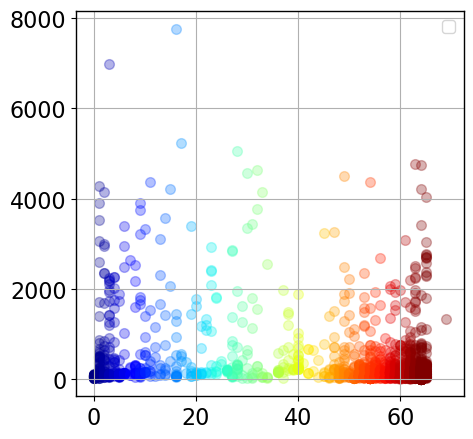

In [24]:
plt.figure(figsize=(5,5))

for i in range(len(unique_elements)):
    plt.scatter(Na_formation[i],E_formation[i], alpha=0.3, color=cm.jet(unique_elements[i]/64))

plt.grid()
plt.legend()

In [20]:
from scipy.spatial import ConvexHull
Na_formation = [element for row in Na_formation for element in row]
E_formation = [element for row in E_formation for element in row]

points = np.transpose(np.array((Na_formation,E_formation)))
points.shape

(2014, 2)

(-10.0, 200.0)

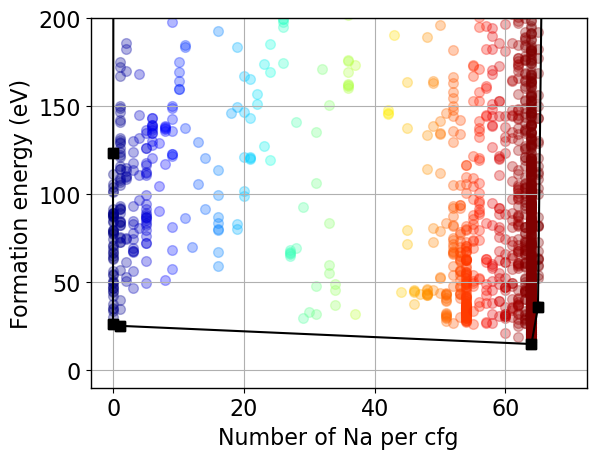

In [27]:
# Compute the convex hull
hull = ConvexHull(points)

# Plot the points and the convex hull
for i in range(len(unique_elements)):
    plt.scatter(Na_formation[i],E_formation[i], alpha=0.3, color=cm.jet(unique_elements[i]/64))
    
for simplex in hull.simplices:
    plt.plot(points[simplex, 0], points[simplex, 1], 'k-', marker='s')  # Draw edges of the hull

plt.xlabel('Number of Na per cfg')
plt.ylabel('Formation energy (eV)')

plt.grid()
plt.ylim(-10,200)

## not important

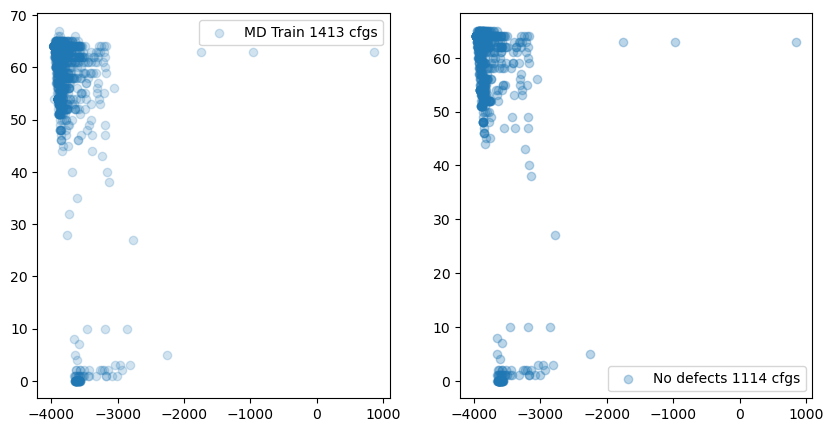

In [19]:
filename_2 = './test_12_cfg/train.cfg'
E_train, F_train, S_train = load_multi_section_cfg(filename_2)

F_train = np.array(F_train, dtype=object)
C_count_train = []
Mn_count_train = []
Fe_count_train = []
N_count_train = []
Na_count_train = []
atom_count_train = []
for i in range(len(F_train)):
    C_count_train.append(np.sum(F_train[:][i] == 0))
    Mn_count_train.append(np.sum(F_train[:][i] == 1))
    Fe_count_train.append(np.sum(F_train[:][i] == 2))
    N_count_train.append(np.sum(F_train[:][i] == 3))
    Na_count_train.append(np.sum(F_train[:][i] == 4))
    atom_count_train.append(F_train[i].shape[0])

C_count_train = np.array(C_count_train)
Mn_count_train = np.array(Mn_count_train)
Fe_count_train = np.array(Fe_count_train)
N_count_train = np.array(N_count_train)
Na_count_train = np.array(Na_count_train)
atom_count_train = np.array(atom_count_train)
E_train = np.array(E_train)

condition = (C_count_train == 192) & (Mn_count_train == 32) & (Fe_count_train == 32) & (N_count_train == 192)
no_defect_indice = np.where(condition)
len(no_defect_indice[0])

condition = atom_count_train > 200
MD_indice = np.where(condition)
len(MD_indice[0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))
ax1.scatter(E_train[MD_indice[0]], Na_count_train[MD_indice[0]], alpha=0.2, label=f'MD Train {len(MD_indice[0])} cfgs')
ax2.scatter(E_train[no_defect_indice[0]], Na_count_train[no_defect_indice[0]], alpha=0.3, label=f'No defects {len(no_defect_indice[0])} cfgs')

ax1.legend()
ax2.legend()

In [18]:
E_train.shape

(2167,)

In [39]:
F_act = np.array(F_act, dtype=object)
Na_count = []
atom_count = []
for i in range(len(E_act)):
    Na_count.append(np.sum(F_act[:][i] == 4))
    atom_count.append(F_act[i].shape[0])

Na_count = np.array(Na_count)
atom_count = np.array(atom_count)

condition_1 = (atom_count > 400) & (E_act < -3000)
condition_2 = atom_count < 200
reasonable_indices_1 = np.where(condition_1)
reasonable_indices_2 = np.where(condition_2)

In [54]:
reasonable_indices_1[0],reasonable_indices_2[0]

ValueError: operands could not be broadcast together with shapes (1092,) (730,) 

In [49]:
reasonable_indices = np.concatenate((reasonable_indices_1[0],reasonable_indices_2[0]))
reasonable_indices

array([ 730,  731,  732, ...,  729, 1938, 1939])

In [52]:
len(E_act)-reasonable_indices.shape[0]

115

In [ ]:
# E_formation = E - xE_Na2 -(1-x)E_Na0, at certain x
# 1. only select the MD structure, and remove those cfgs with defecta
# 2. seperate E into E of different number of Na
E_Na2 = -995*4
E_Na0 = -920*4
E_formation = E_train - 


## Before removal

### Load

In [25]:
filename = './test_12_cfg/cal_selected.cfg.0'
E_MTP,supercell, F_MTP, S_MTP = load_multi_section_cfg_no_grade(filename)
E_MTP

array([ 8441.26660504,  -462.78597639,  1906.66945491, -1000.60268676,
        -370.6015788 ,  4037.16240573,  2435.04576394,  4128.49726988])

In [26]:
condition = (E_MTP<200)
E_MTP_good = np.where(condition)

In [30]:
E_MTP[E_MTP_good[0]]

array([ -462.78597639, -1000.60268676,  -370.6015788 ])

In [11]:
## Usage
filename = './test_12_cfg/test_training_set/efs_cfg_train_150.cfg.0'
E_MTP,supercell, F_MTP, S_MTP = load_multi_section_cfg_no_grade(filename)
# Usage
filename = './test_12_cfg/test_training_set/train_force_150.cfg'
E_DFT, supercell, F_DFT, S_DFT = load_multi_section_cfg_no_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)
F_MTP = np.array(F_MTP, dtype=object)
x = np.concatenate([arr[:,5:].flatten() for arr in F_DFT])
y = np.concatenate([arr[:,5:].flatten() for arr in F_MTP])

In [63]:
## Usage
filename = './test_12_cfg/test_training_set/efs_cfg_train_50.cfg.0'
E_MTP,supercell, F_MTP, S_MTP = load_multi_section_cfg_no_grade(filename)
# Usage
filename = './test_12_cfg/test_training_set/train_force_50.cfg'
E_DFT, supercell, F_DFT, S_DFT = load_multi_section_cfg_no_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)
F_MTP = np.array(F_MTP, dtype=object)
x = np.concatenate([arr[:,5:].flatten() for arr in F_DFT])
y = np.concatenate([arr[:,5:].flatten() for arr in F_MTP])

### Force

In [41]:
E_DFT.shape, E_MTP.shape


((2786,), (1590,))

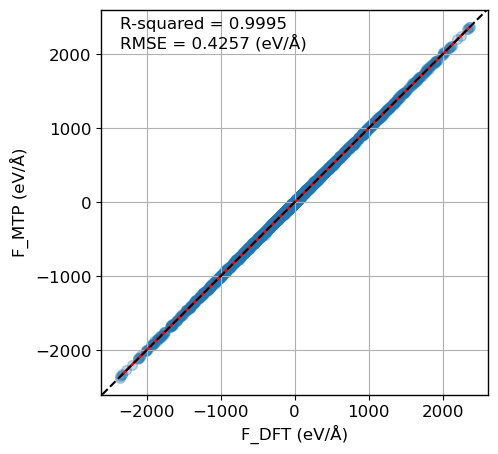

In [64]:
x = np.concatenate([arr[:,5:].flatten() for arr in F_DFT])
y = np.concatenate([arr[:,5:].flatten() for arr in F_MTP])

fig = plt.figure(figsize=(5,5))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE = {rmse:.4f} (eV/Å)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('F_DFT (eV/Å)')
plt.ylabel('F_MTP (eV/Å)')

# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.savefig('force_cfg_force_50.png', dpi=300, bbox_inches='tight')

### Energy

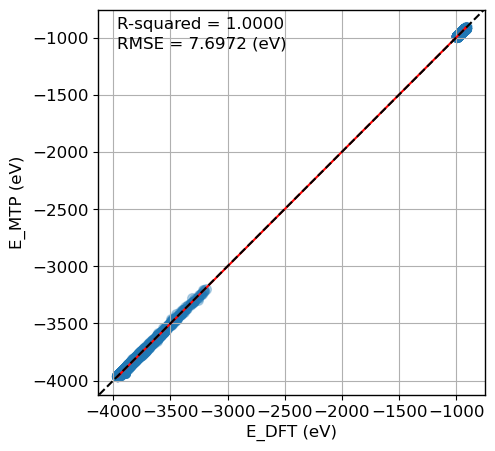

In [65]:
x = E_DFT
y = E_MTP

fig = plt.figure(figsize=(5,5))

slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE = {rmse:.4f} (eV)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('E_DFT (eV)')
plt.ylabel('E_MTP (eV)')

# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.savefig('energy_cfg_force_50.png', dpi=300, bbox_inches='tight')

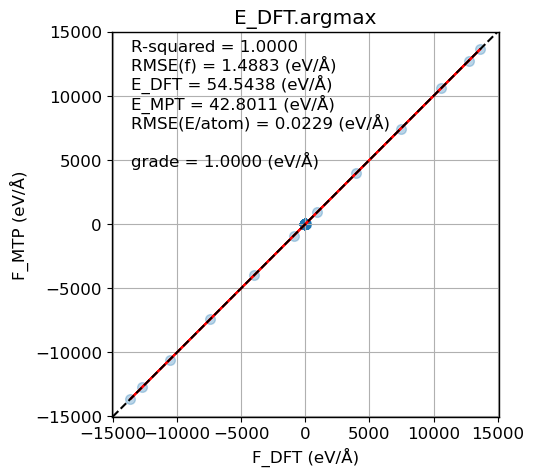

In [92]:
plt.rcParams.update({'font.size': 12})
i=E_DFT.argmax()
x = np.concatenate([arr[5:].flatten() for arr in F_DFT[i]])
y = np.concatenate([arr[5:].flatten() for arr in F_MTP[i]])
delta_E = E_DFT[i] - E_MTP[i]

fig = plt.figure(figsize=(5,5))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE(f) = {rmse:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.85, f'E_DFT = {E_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.80, f'E_MPT = {E_MTP[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.75, f'RMSE(E/atom) = {abs(delta_E/F_DFT[i].shape[0]):.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.65, f'grade = {grade_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('F_DFT (eV/Å)')
plt.ylabel('F_MTP (eV/Å)')
plt.title('E_DFT.argmax')

# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.savefig('E_DFT.argmax_nbh.png', dpi=300, bbox_inches='tight')

In [19]:
arr = E_DFT

sorted_values = sorted(E_DFT)
smallest = sorted_values[99]
indices = [i for i, v in enumerate(arr) if v == smallest]

print("Indices of the 100th smallest value:", indices_of_100th_smallest)
print("100th smallest value:", value_100th_smallest)


Indices of the 100th smallest value: [1237]
100th smallest value: -3949.97321243


In [22]:
i[0]

1237

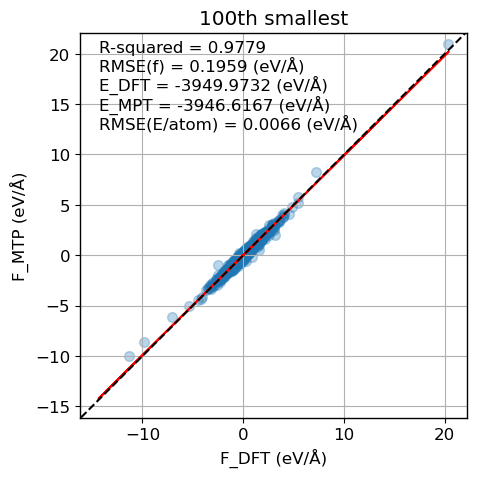

In [68]:
plt.rcParams.update({'font.size': 12})

j=100
sorted_values = sorted(E_DFT)
smallest = sorted_values[j-1]
indices = [i for i, v in enumerate(arr) if v == smallest]
i=indices[0]

x = np.concatenate([arr[5:].flatten() for arr in F_DFT[i]])
y = np.concatenate([arr[5:].flatten() for arr in F_MTP[i]])
delta_E = E_DFT[i] - E_MTP[i]

fig = plt.figure(figsize=(5,5))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE(f) = {rmse:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.85, f'E_DFT = {E_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.80, f'E_MPT = {E_MTP[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.75, f'RMSE(E/atom) = {abs(delta_E/F_DFT[i].shape[0]):.4f} (eV/Å)', transform=plt.gca().transAxes)
#plt.text(0.05, 0.65, f'grade = {grade_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('F_DFT (eV/Å)')
plt.ylabel('F_MTP (eV/Å)')
plt.title(f'{j}th smallest')
# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.savefig(f'{j}th_cfg_force_50.png', dpi=300, bbox_inches='tight')

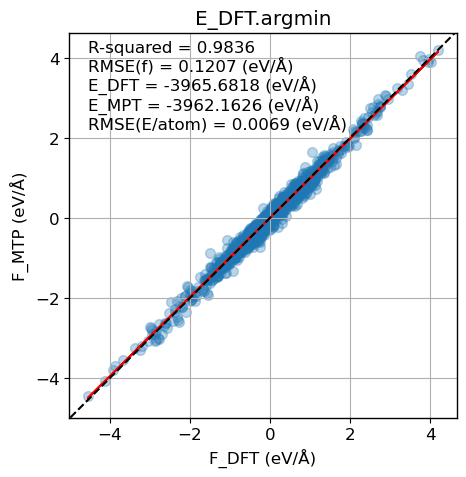

In [66]:
plt.rcParams.update({'font.size': 12})
i=E_DFT.argmin()
x = np.concatenate([arr[5:].flatten() for arr in F_DFT[i]])
y = np.concatenate([arr[5:].flatten() for arr in F_MTP[i]])
delta_E = E_DFT[i] - E_MTP[i]

fig = plt.figure(figsize=(5,5))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE(f) = {rmse:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.85, f'E_DFT = {E_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.80, f'E_MPT = {E_MTP[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.75, f'RMSE(E/atom) = {abs(delta_E/F_DFT[i].shape[0]):.4f} (eV/Å)', transform=plt.gca().transAxes)
#plt.text(0.05, 0.65, f'grade = {grade_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('F_DFT (eV/Å)')
plt.ylabel('F_MTP (eV/Å)')
plt.title('E_DFT.argmin')
# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.savefig('E_DFT.argmin_cfg_force_50.png', dpi=300, bbox_inches='tight')

(-46.364142449999996, 46.903041449999996)

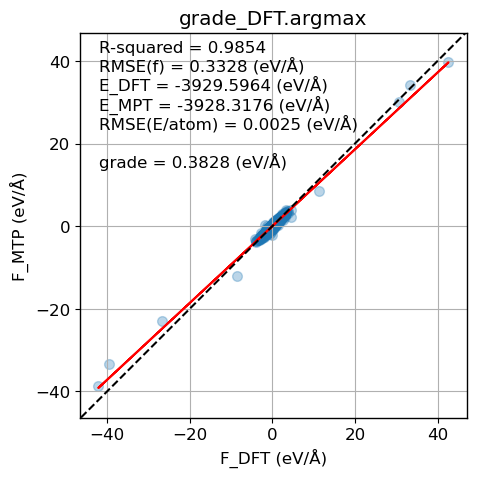

In [95]:
plt.rcParams.update({'font.size': 12})
i=900
x = np.concatenate([arr[5:].flatten() for arr in F_DFT[i]])
y = np.concatenate([arr[5:].flatten() for arr in F_MTP[i]])
delta_E = E_DFT[i] - E_MTP[i]

fig = plt.figure(figsize=(5,5))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE(f) = {rmse:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.85, f'E_DFT = {E_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.80, f'E_MPT = {E_MTP[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.75, f'RMSE(E/atom) = {abs(delta_E/F_DFT[i].shape[0]):.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.65, f'grade = {grade_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('F_DFT (eV/Å)')
plt.ylabel('F_MTP (eV/Å)')
plt.title('grade_DFT.argmax')
# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

#plt.savefig('grade_DFT.argmax.png', dpi=300, bbox_inches='tight')

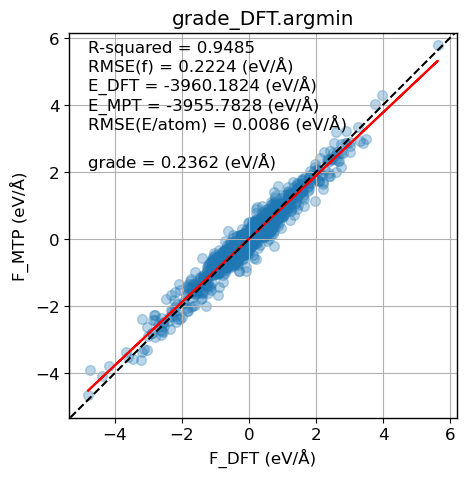

In [71]:
plt.rcParams.update({'font.size': 12})
i=grade_DFT.argmin()
x = np.concatenate([arr[5:].flatten() for arr in F_DFT[i]])
y = np.concatenate([arr[5:].flatten() for arr in F_MTP[i]])
delta_E = E_DFT[i] - E_MTP[i]

fig = plt.figure(figsize=(5,5))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE(f) = {rmse:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.85, f'E_DFT = {E_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.80, f'E_MPT = {E_MTP[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.75, f'RMSE(E/atom) = {abs(delta_E/F_DFT[i].shape[0]):.4f} (eV/Å)', transform=plt.gca().transAxes)
plt.text(0.05, 0.65, f'grade = {grade_DFT[i]:.4f} (eV/Å)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('F_DFT (eV/Å)')
plt.ylabel('F_MTP (eV/Å)')
plt.title('grade_DFT.argmin')
# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.savefig('grade_DFT.argmin.png', dpi=300, bbox_inches='tight')

### High grade checking

In [31]:
fig = plt.figure(figsize=(5,5))
x = np.concatenate([arr[:,5:-1].flatten() for arr in F_DFT])
grade = np.concatenate([arr[:,-1].flatten() for arr in F_DFT])


<Figure size 500x500 with 0 Axes>

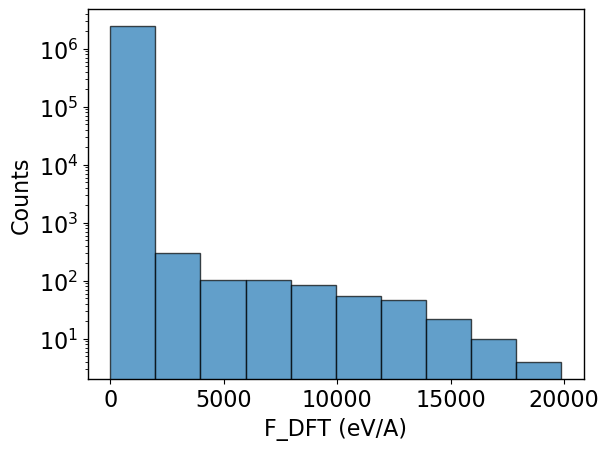

In [32]:

#bin_edges = np.arange(0,300,10)
plt.hist(abs(x), edgecolor='black', alpha=0.7)#,bins=bin_edges)
plt.xlabel('F_DFT (eV/A)')
plt.ylabel('Counts')
plt.yscale('log')

<function ndarray.max>

In [33]:
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(1,2,0.1)
plt.hist(abs(x-y), edgecolor='black', alpha=0.7,bins=bin_edges)
plt.xlabel('Error per atom (eV/A)')
plt.ylabel('Counts')
#plt.savefig('cfg count.png', dpi=300, bbox_inches='tight')

ValueError: operands could not be broadcast together with shapes (2466256,) (3047,) 

<Figure size 500x500 with 0 Axes>

Text(0, 0.5, 'CFG Counts')

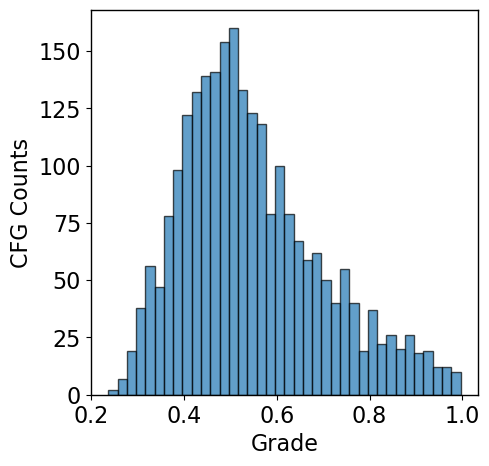

In [34]:
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(grade_DFT.min(), grade_DFT.max(), 0.02)
plt.hist(grade_DFT, edgecolor='black',bins=bin_edges, alpha=0.7)
plt.xlabel('Grade')
plt.ylabel('CFG Counts')
#plt.savefig('cfg count.png', dpi=300, bbox_inches='tight')

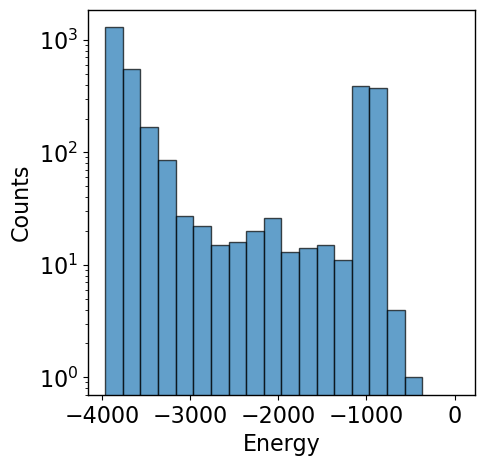

In [35]:
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(E_DFT.min(), E_DFT.max(), 200)
plt.hist(E_DFT, edgecolor='black',bins=bin_edges, alpha=0.7)
plt.xlabel('Energy')
plt.ylabel('Counts')
plt.yscale('log')
#plt.savefig('cfg count.png', dpi=300, bbox_inches='tight')

## After removal

In [42]:
## Usage
filename = './efs_train.cfg.0'
E_MTP, F_MTP, S_MTP = load_multi_section_cfg(filename)
# Usage
filename = './grade_train.cfg.0'
E_DFT, supercell, F_DFT, S_DFT, grade_DFT = load_multi_section_cfg_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)
F_MTP = np.array(F_MTP, dtype=object)
grade = np.concatenate([arr[:,-1].flatten() for arr in F_DFT])

active_set = np.where(E_DFT < -900)

F_DFT = np.array(F_DFT, dtype=object)
F_DFT = F_DFT[active_set[0]]

F_MTP = np.array(F_MTP, dtype=object)
F_MTP = F_MTP[active_set[0]]

F_MTP.shape, F_DFT.shape

((1854,), (1854,))

(-33784.63914115854, 33786.43381758825)

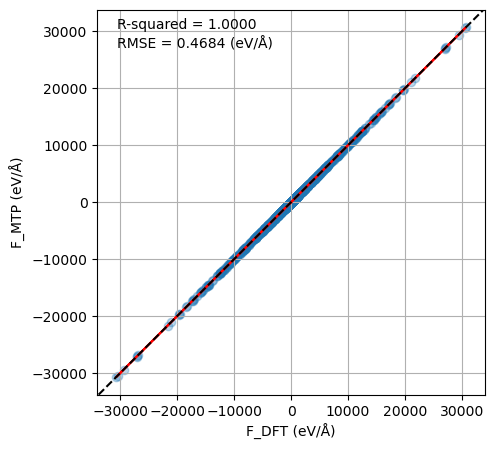

In [43]:
fig = plt.figure(figsize=(5,5))

x = np.concatenate([arr[:,5:].flatten() for arr in F_DFT])
y = np.concatenate([arr[:,4:].flatten() for arr in F_MTP])

slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE = {rmse:.4f} (eV/Å)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('F_DFT (eV/Å)')
plt.ylabel('F_MTP (eV/Å)')

# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

#plt.savefig('force.png', dpi=300, bbox_inches='tight')

Text(0, 0.5, 'Counts')

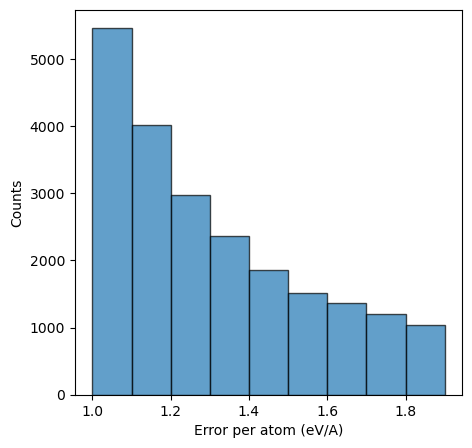

In [44]:
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(1,2,0.1)
plt.hist(abs(x-y), edgecolor='black', alpha=0.7,bins=bin_edges)
plt.xlabel('Error per atom (eV/A)')
plt.ylabel('Counts')
#plt.savefig('cfg count.png', dpi=300, bbox_inches='tight')

Text(0, 0.5, 'CFG Counts')

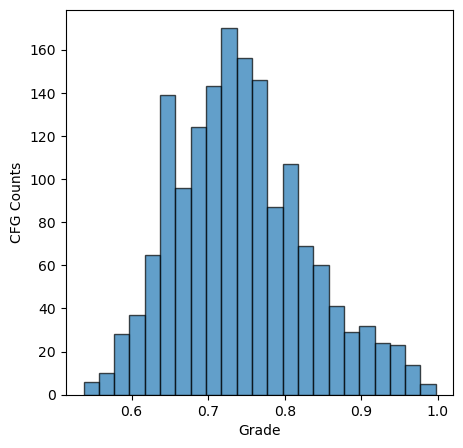

In [45]:
grade = grade_DFT
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(grade_DFT.min(), grade_DFT.max(), 0.02)
plt.hist(grade_DFT, edgecolor='black',bins=bin_edges, alpha=0.7)
plt.xlabel('Grade')
plt.ylabel('CFG Counts')
#plt.savefig('cfg count.png', dpi=300, bbox_inches='tight')

In [11]:
grade.max(), grade_MTP.max()

NameError: name 'grade' is not defined

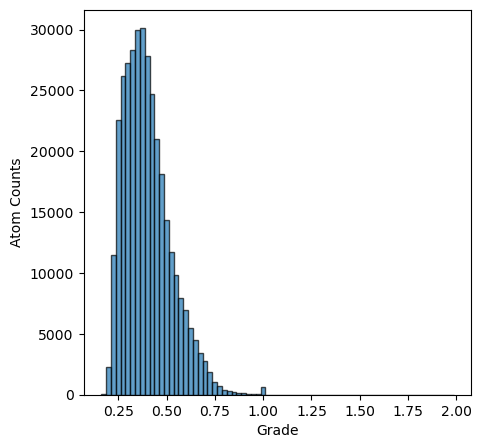

In [22]:
grade = np.concatenate([arr[:,-1].flatten() for arr in F_MTP])
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(grade.min(), 2, 0.025)
plt.hist(grade, edgecolor='black',bins=bin_edges, alpha=0.7)
plt.xlabel('Grade')
plt.ylabel('Atom Counts')
plt.savefig('atom count.png', dpi=300, bbox_inches='tight')

In [ ]:
## Usage
filename = './efs_train.cfg.0'
E_MTP, F_MTP, S_MTP = load_multi_section_cfg(filename)
# Usage
filename = './grade_train.cfg.0'
E_DFT, supercell, F_DFT, S_DFT, grade_DFT = load_multi_section_cfg_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)
F_MTP = np.array(F_MTP, dtype=object)
x = np.concatenate([arr[:,5:].flatten() for arr in F_DFT])
y = np.concatenate([arr[:,4:].flatten() for arr in F_MTP])

(-4539.811299997145, 8041.252988210807)

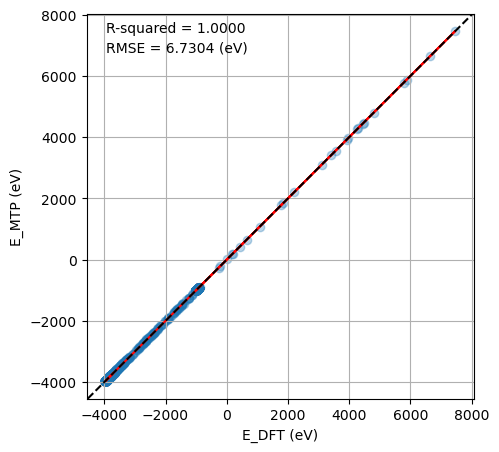

In [35]:
fig = plt.figure(figsize=(5,5))
x = E_DFT
y = E_MTP

slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

line = slope * x + intercept
plt.plot(x, line, color='red', label=f'Regression line')# (y = {slope:.2f}x + {intercept:.2f})')

rmse = calculate_rmse(y, x)

plt.text(0.05, 0.95, f'R-squared = {r_value**2:.4f}', transform=plt.gca().transAxes)
plt.text(0.05, 0.90, f'RMSE = {rmse:.4f} (eV)', transform=plt.gca().transAxes)

min_val = min(plt.xlim()[0], plt.ylim()[0])
max_val = max(plt.xlim()[1], plt.ylim()[1])
plt.plot([min_val, max_val], [min_val, max_val], 'k--')

plt.scatter(x, y, alpha=0.3)
plt.xlabel('E_DFT (eV)')
plt.ylabel('E_MTP (eV)')

# Add legend
#plt.legend()

# Ensure equal aspect ratio
plt.axis('equal')

# Show the plot
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
#plt.savefig('energy.png', dpi=300, bbox_inches='tight')

## Energy

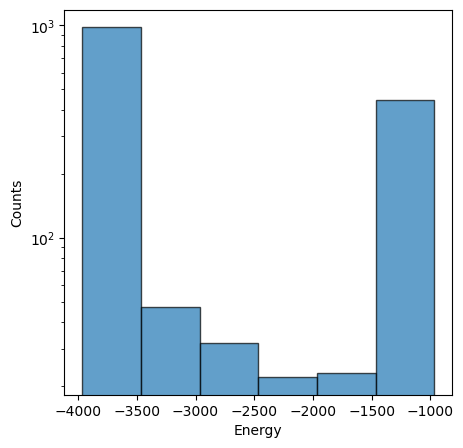

In [134]:
filename = './grade_train.cfg.0'
E_DFT, supercell, F_DFT, S_DFT, grade_DFT = load_multi_section_cfg_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(E_DFT.min(), E_DFT.max(), 500)
plt.hist(E_DFT, edgecolor='black',bins=bin_edges, alpha=0.7)
plt.xlabel('Energy')
plt.ylabel('Counts')
plt.yscale('log')
#plt.savefig('cfg count.png', dpi=300, bbox_inches='tight')

In [36]:
atom_num_ls = []
for i in range(len(E_DFT)):
    atom_num_ls.append(F_DFT[i].shape[0])

(420.0, 530.0)

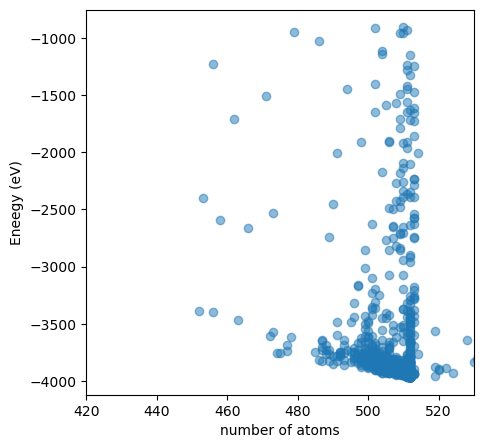

In [38]:
fig = plt.figure(figsize=(5,5))
plt.scatter(atom_num_ls,E_DFT,alpha=0.5)
plt.xlabel('number of atoms')
plt.ylabel('Eneegy (eV)')
plt.xlim(420,530)

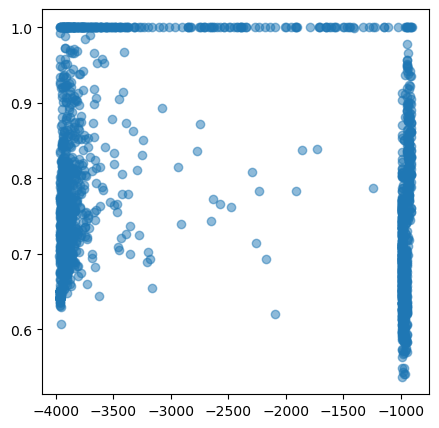

In [39]:
fig = plt.figure(figsize=(5,5))
plt.scatter(E_DFT,grade_DFT,alpha=0.5)

## Force Analysis
are atoms of higher force of higher grade also?

In [43]:
## Usage
filename = './grade_train.cfg.0'
E_DFT, supercell, F_DFT, S_DFT, grade_DFT = load_multi_section_cfg_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)

coordinate = np.concatenate([arr[:,2:5].flatten() for arr in F_DFT])
x = np.concatenate([arr[:,5:-1].flatten() for arr in F_DFT])
grade = np.concatenate([arr[:,-1].flatten() for arr in F_DFT])

In [34]:
F_square = []
distance = []
for i in range(len(grade)):
    F_square.append(np.linalg.norm(x[3*i : 3*i+3]))
    distance.append(np.linalg.norm(coordinate[3*i : 3*i+3]))

NameError: name 'coordinate' is not defined

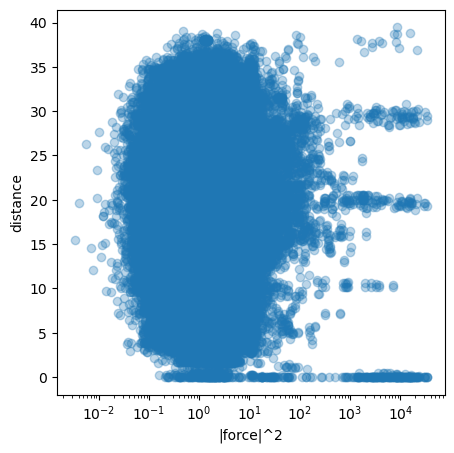

In [45]:
fig = plt.figure(figsize=(5,5))
plt.scatter(F_square, distance, alpha=0.3)
plt.xlabel('|force|^2')
plt.ylabel('distance')
#plt.ylim(0.95,1.)
plt.xscale('log')

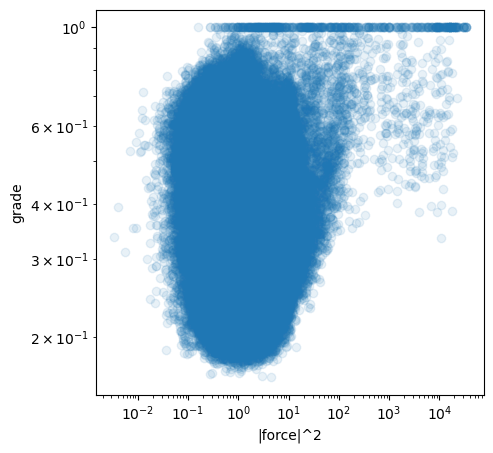

In [47]:
fig = plt.figure(figsize=(5,5))
plt.scatter(F_square, grade, alpha=0.1)
plt.xlabel('|force|^2')
plt.ylabel('grade')
#plt.ylim(0.95,1.)
plt.xscale('log')
plt.yscale('log')

Text(0, 0.5, 'grade')

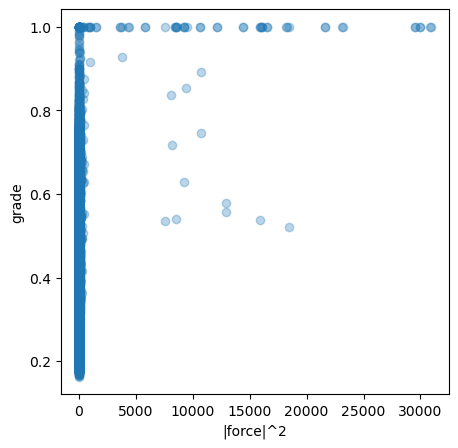

In [41]:
fig = plt.figure(figsize=(5,5))
plt.scatter(F_square[500000:], grade[500000:], alpha=0.3)
plt.xlabel('|force|^2')
plt.ylabel('grade')

Text(0.5, 1.0, './new_selected_2.cfg')

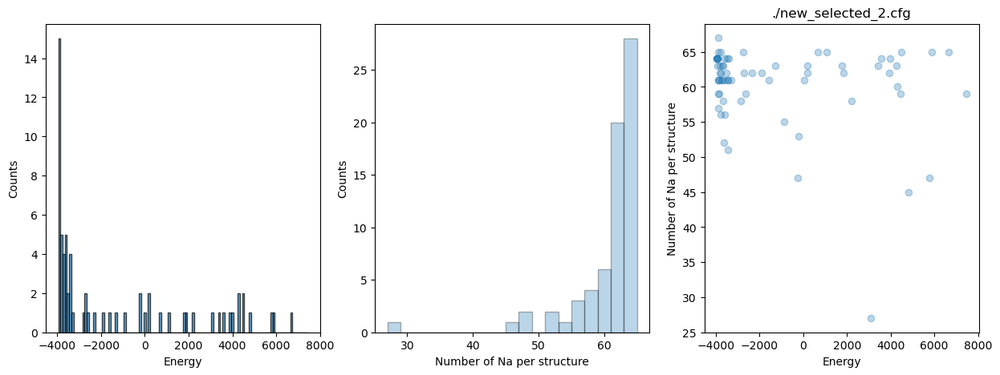

In [26]:
filename = './new_selected_2.cfg'
E_act, F_act, S_act = load_multi_section_cfg(filename)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))
bin_edges = np.arange(E_act.min(), E_act.max(),100)
ax1.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.7)
ax1.set_xlabel('Energy')
ax1.set_ylabel('Counts')

F_act = np.array(F_act, dtype=object)
Na_count = []
for i in range(len(E_act)):
    Na_count.append(np.sum(F_act[:][i] == 4))

bin_edges = np.arange(min(Na_count), max(Na_count),2)
ax2.hist(Na_count, edgecolor='black',bins=bin_edges, alpha=0.3)
ax2.set_xlabel('Number of Na per structure')
ax2.set_ylabel('Counts')

ax3.scatter(E_act,Na_count,alpha=0.3)
ax3.set_ylabel('Number of Na per structure')
ax3.set_xlabel('Energy')

plt.title(filename)

In [28]:
largest_indices = np.argpartition(E_act, -30)[-30:]
# Sort these indices to get them in descending order by value
largest_indices = largest_indices[np.argsort(E_act[largest_indices])[::-1]]
print("Indices of the 10 largest values:", largest_indices)
print("10 largest values:", E_act[largest_indices])

Indices of the 10 largest values: [54 39 42 65 59 63 62 52 45 44 51 41 55 58 56 43 49 50 68 47 60 57 67 66
 64 29 27 40  9 19]
10 largest values: [ 7466.01679402  6642.42899744  5876.31767118  5788.32409448
  4819.48044901  4492.29095754  4454.73433324  4297.03225045
  4267.89253047  3966.62748468  3927.49684741  3565.36082465
  3411.40267654  3108.13448174  2210.98793856  1842.98781092
  1765.61095879  1085.04607707   654.36884897   193.06679608
   183.65359786    25.2183134   -210.54352286  -253.99960447
  -869.70813636 -1277.16376462 -1583.70891246 -1909.97431873
 -2342.27185997 -2622.72247703]


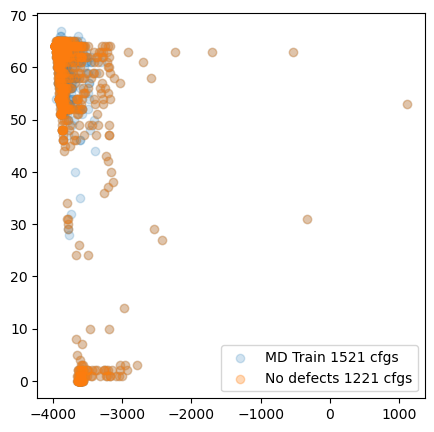

In [13]:
filename_2 = './test_12_cfg/train.cfg'
E_train, F_train, S_train = load_multi_section_cfg(filename_2)

F_train = np.array(F_train, dtype=object)
C_count_train = []
Mn_count_train = []
Fe_count_train = []
N_count_train = []
Na_count_train = []
atom_count_train = []
for i in range(len(F_train)):
    C_count_train.append(np.sum(F_train[:][i] == 0))
    Mn_count_train.append(np.sum(F_train[:][i] == 1))
    Fe_count_train.append(np.sum(F_train[:][i] == 2))
    N_count_train.append(np.sum(F_train[:][i] == 3))
    Na_count_train.append(np.sum(F_train[:][i] == 4))
    atom_count_train.append(F_train[i].shape[0])

C_count_train = np.array(C_count_train)
Mn_count_train = np.array(Mn_count_train)
Fe_count_train = np.array(Fe_count_train)
N_count_train = np.array(N_count_train)
Na_count_train = np.array(Na_count_train)
atom_count_train = np.array(atom_count_train)
E_train = np.array(E_train)

condition = (C_count_train == 192) & (Mn_count_train == 32) & (Fe_count_train == 32) & (N_count_train == 192)
no_defect_indice = np.where(condition)
len(no_defect_indice[0])

condition = atom_count_train > 200
MD_indice = np.where(condition)
len(MD_indice[0])

plt.figure(figsize=(5,5))
plt.scatter(E_train[MD_indice[0]], Na_count_train[MD_indice[0]], alpha=0.2, label=f'MD Train {len(MD_indice[0])} cfgs')
plt.scatter(E_train[no_defect_indice[0]], Na_count_train[no_defect_indice[0]], alpha=0.3, label=f'No defects {len(no_defect_indice[0])} cfgs')

plt.legend()

## Potential analysis

Text(0.5, 1.0, './train.cfg')

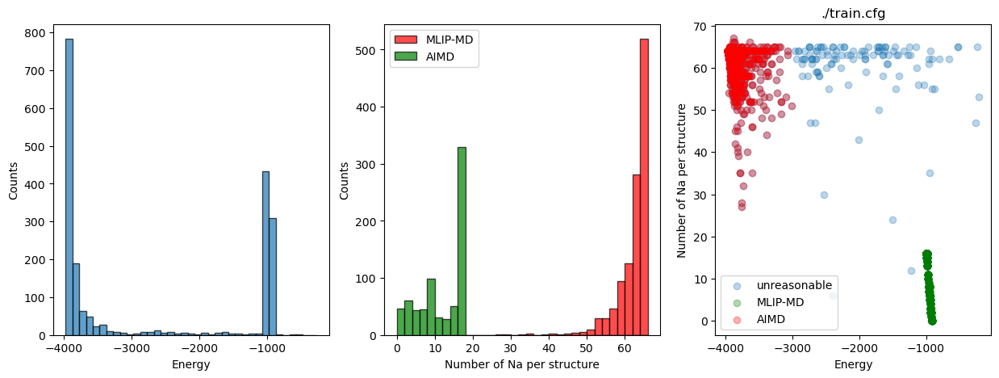

In [48]:
# Usage
filename = './train.cfg'
E_act, F_act, S_act = load_multi_section_cfg(filename)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))
bin_edges = np.arange(E_act.min(), E_act.max(),100)
ax1.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.7)
ax1.set_xlabel('Energy')
ax1.set_ylabel('Counts')

F_act = np.array(F_act, dtype=object)
Na_count = []
atom_count = []
for i in range(len(E_act)):
    Na_count.append(np.sum(F_act[:][i] == 4))
    atom_count.append(F_act[i].shape[0])

Na_count = np.array(Na_count)
atom_count = np.array(atom_count)
E_act = np.array(E_act)

condition_1 = (atom_count > 400) & (E_act < -3000)
condition_2 = atom_count < 200
reasonable_indices_1 = np.where(condition_1)
reasonable_indices_2 = np.where(condition_2)

bin_edges = np.arange(min(Na_count), max(Na_count),2)
ax2.hist(Na_count[reasonable_indices_1[0]], edgecolor='black',bins=bin_edges, alpha=0.7, color='red', label='MLIP-MD')
ax2.hist(Na_count[reasonable_indices_2[0]], edgecolor='black',bins=bin_edges, alpha=0.7, color='green', label='AIMD')
ax2.set_xlabel('Number of Na per structure')
ax2.set_ylabel('Counts')
ax2.legend()

ax3.scatter(E_act, Na_count, alpha=0.3, label='unreasonable')
ax3.scatter(E_act[reasonable_indices_2[0]], Na_count[reasonable_indices_2[0]], alpha=0.3, color='green', label='MLIP-MD')
ax3.scatter(E_act[reasonable_indices_1[0]], Na_count[reasonable_indices_1[0]], alpha=0.3, color='red', label='AIMD')
ax3.legend()
ax3.set_ylabel('Number of Na per structure')
ax3.set_xlabel('Energy')

plt.title(filename)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Text(0.5, 1.0, './train.cfg')

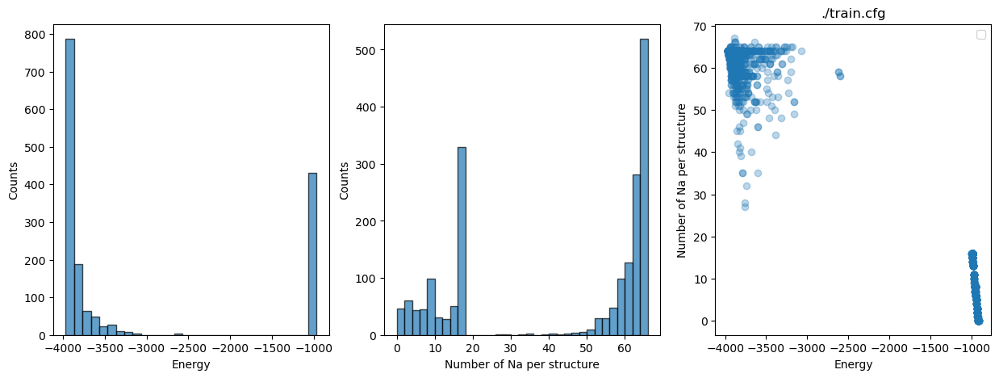

In [109]:
# Usage
filename = './train.cfg'
E_act, F_act, S_act = load_multi_section_cfg(filename)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))
bin_edges = np.arange(E_act.min(), E_act.max(),100)
ax1.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.7)
ax1.set_xlabel('Energy')
ax1.set_ylabel('Counts')

F_act = np.array(F_act, dtype=object)
Na_count = []
C_count = []
N_count = []
atom_count = []
for i in range(len(E_act)):
    C_count.append(np.sum(F_act[:][i] == 0))
    N_count.append(np.sum(F_act[:][i] == 3))
    Na_count.append(np.sum(F_act[:][i] == 4))
    atom_count.append(F_act[i].shape[0])

Na_count = np.array(Na_count)
C_count = np.array(C_count)
N_count = np.array(N_count)
atom_count = np.array(atom_count)
E_act = np.array(E_act)

condition_1 = (atom_count > 400) & (E_act < -3000)
condition_2 = atom_count < 200
reasonable_indices_1 = np.where(condition_1)
reasonable_indices_2 = np.where(condition_2)

bin_edges = np.arange(min(Na_count), max(Na_count),2)
ax2.hist(Na_count, edgecolor='black',bins=bin_edges, alpha=0.7)
ax2.set_xlabel('Number of Na per structure')
ax2.set_ylabel('Counts')

ax3.scatter(E_act, Na_count, alpha=0.3)
ax3.legend()
ax3.set_ylabel('Number of Na per structure')
ax3.set_xlabel('Energy')
#ax3.set_xlim(-4000,-3000)
#ax3.set_ylim(25,70)

plt.title(filename)

In [68]:
N_count[-50:].mean(),C_count[-50:].mean()

(191.9, 190.96)

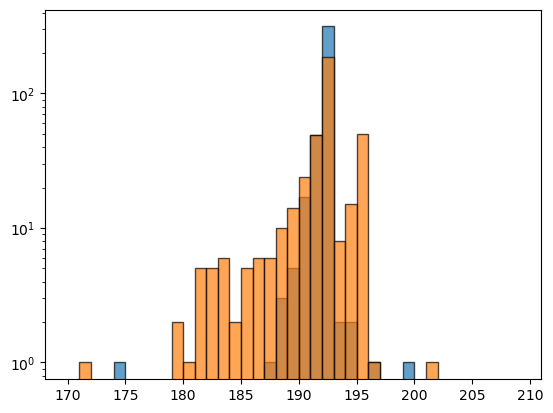

In [69]:
plt.figure()
bin_edges = np.arange(170,210,1)
plt.hist(N_count[-400:],edgecolor='black',bins=bin_edges, alpha=0.7)
plt.hist(C_count[-400:],edgecolor='black',bins=bin_edges, alpha=0.7)
plt.yscale('log')

In [79]:
import math
x = np.concatenate([arr[:,5:-1].flatten() for arr in F_act])
F = []
for i in range(len(x)):
    F.append(math.sqrt(np.linalg.norm(x[3*i : 3*i+3])))
F=np.array(F)

In [80]:
F.min(), F.max()

(0.0, 197.45415857009448)

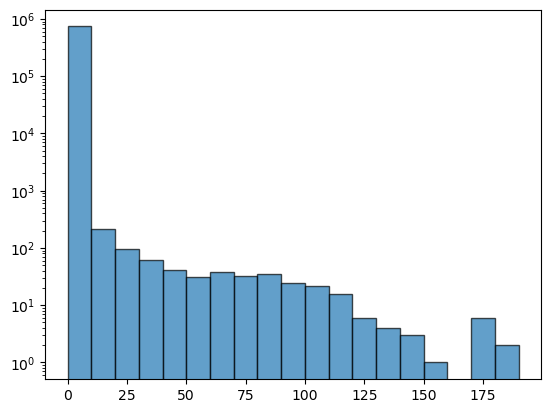

In [81]:
plt.figure()
bin_edges = np.arange(F.min(), F.max(),10)
plt.hist(F,edgecolor='black',bins=bin_edges, alpha=0.7)
plt.yscale('log')

In [82]:
np.sum(F > 70)

154

Text(0.5, 1.0, './pot_save/curr.almtp')

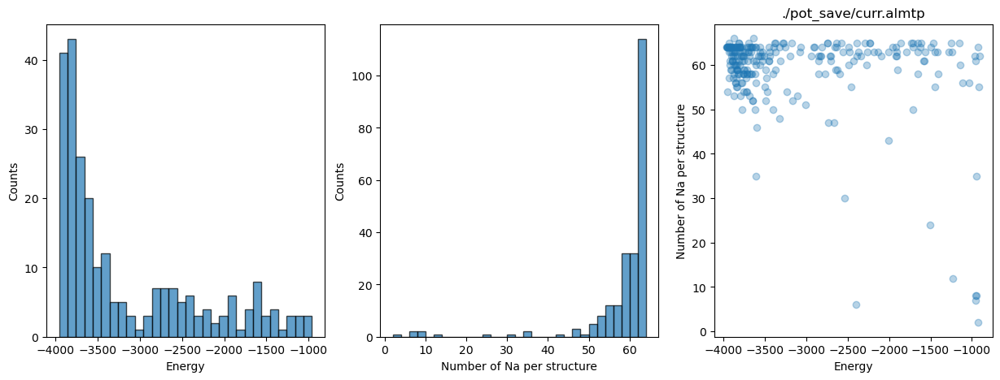

In [42]:
# Usage
filename = './pot_save/curr.almtp'
E_act, F_act, S_act = load_multi_section_cfg(filename)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))
bin_edges = np.arange(E_act.min(), E_act.max(),100)
ax1.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.7)
ax1.set_xlabel('Energy')
ax1.set_ylabel('Counts')

F_act = np.array(F_act, dtype=object)
Na_count = []
for i in range(len(E_act)):
    Na_count.append(np.sum(F_act[:][i] == 4))

bin_edges = np.arange(min(Na_count), max(Na_count),2)
ax2.hist(Na_count, edgecolor='black',bins=bin_edges, alpha=0.7)
ax2.set_xlabel('Number of Na per structure')
ax2.set_ylabel('Counts')

ax3.scatter(E_act,Na_count,alpha=0.32)
ax3.set_ylabel('Number of Na per structure')
ax3.set_xlabel('Energy')

plt.title(filename)

((265,), 0)

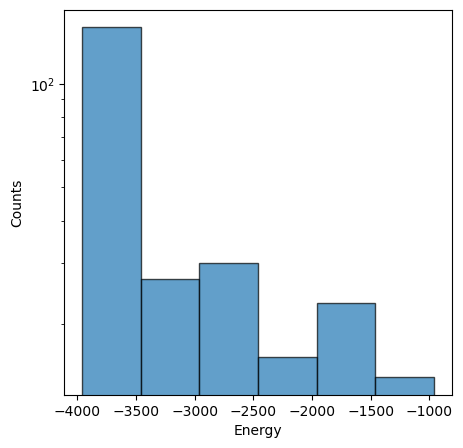

In [11]:
# Usage
filename = './curr.almtp'
E_act, F_act, S_act = load_multi_section_cfg(filename)
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(E_act.min(), E_act.max(), 500)
plt.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.7)
plt.xlabel('Energy')
plt.ylabel('Counts')
plt.yscale('log')
count = np.sum(E_act > -900)
E_act.shape, count

Text(0.5, 1.0, './nbh_20.almtp')

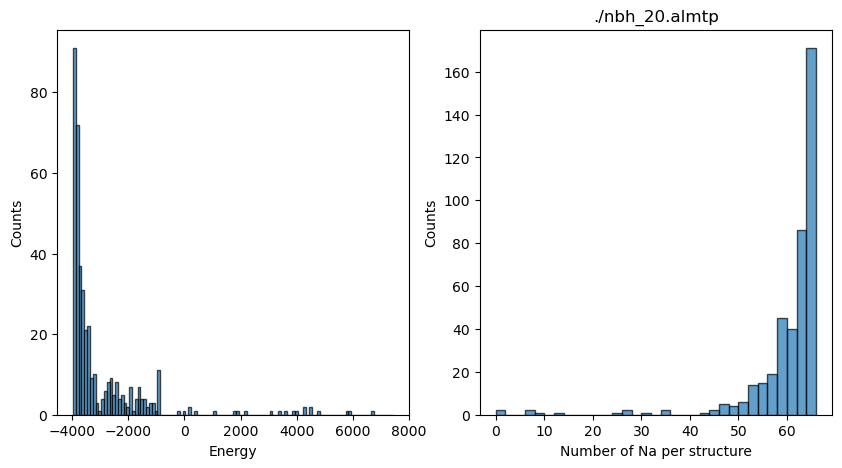

In [66]:
# Usage
filename = './nbh_20.almtp'
E_act, F_act, S_act = load_multi_section_cfg(filename)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))
bin_edges = np.arange(E_act.min(), E_act.max(),100)
ax1.hist(E_act, edgecolor='black',bins=bin_edges, alpha=0.7)
ax1.set_xlabel('Energy')
ax1.set_ylabel('Counts')

F_act = np.array(F_act, dtype=object)
Na_count = []
for i in range(len(E_act)):
    Na_count.append(np.sum(F_act[:][i] == 4))

bin_edges = np.arange(min(Na_count), max(Na_count),2)
ax2.hist(Na_count, edgecolor='black',bins=bin_edges, alpha=0.7)
ax2.set_xlabel('Number of Na per structure')
ax2.set_ylabel('Counts')

plt.title(filename)

In [110]:
count = np.sum((E_DFT < -1000) & (E_DFT > -3000))
count

90

In [24]:
indices = np.where(E_MTP > -900)[0]
grade_MTP[indices]

NameError: name 'grade_MTP' is not defined

In [15]:
# Usage
filename = './cal_train.cfg.0'
E_MTP, supercell, F_MTP, S_MTP, grade_MTP = load_multi_section_cfg_grade(filename)
active_set = np.where(E_MTP < -900)

In [23]:
supercell[0]

array([[ 1.9129434e+01, -6.0900000e-03,  2.1930000e-03],
       [ 1.4527140e+00,  9.4531480e+00, -2.0220000e-03],
       [ 1.4536690e+00,  1.2473060e+00,  9.3749790e+00]])

Text(0, 0.5, 'CFG Counts')

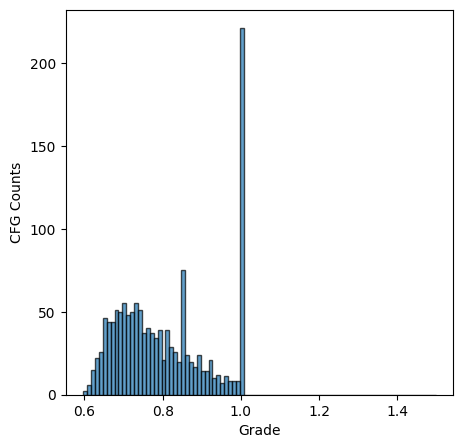

In [17]:
grade = grade_MTP
fig = plt.figure(figsize=(5,5))
bin_edges = np.arange(grade_MTP.min(), 1.5, 0.01)
plt.hist(grade_MTP, edgecolor='black',bins=bin_edges, alpha=0.7)
plt.xlabel('Grade')
plt.ylabel('CFG Counts')
#plt.savefig('cfg count.png', dpi=300, bbox_inches='tight')

## Clean and Write

In [11]:
filename = './train.cfg'
E_DFT, supercell, F_DFT, S_DFT = load_multi_section_cfg_no_grade(filename)

In [12]:
F_DFT = np.array(F_DFT, dtype=object)
Na_count = []
atom_count = []
for i in range(len(E_DFT)):
    Na_count.append(np.sum(F_DFT[:][i] == 4))
    atom_count.append(F_DFT[i].shape[0])

Na_count = np.array(Na_count)
atom_count = np.array(atom_count)
E_DFT = np.array(E_DFT)

In [13]:
condition_1 = (Na_count > 4) & (Na_count < 11)
good_apple_ls = np.where(condition_1)[0]
#bad_apple_ls = np.where(Na_count != i)[0]

In [54]:
import math
F_DFT = np.array(F_DFT, dtype=object)

bad_apple_ls = []

for i in range(len(E_DFT)):
    x = np.concatenate([arr[5:].flatten() for arr in F_DFT[i]])
    F = []
    for j in range(len(x)):
        F.append(math.sqrt(np.linalg.norm(x[3*j : 3*j+3])))
    if any(value > 300 for value in F):
        bad_apple_ls.append(i)

In [55]:
good_apple_ls = [element for idx, element in enumerate(range(len(E_DFT))) if idx not in bad_apple_ls]

In [27]:
len(good_apple_ls),len(bad_apple_ls),len(good_apple_ls)+len(bad_apple_ls)

(710, 2855, 3565)

In [57]:
F_DFT = np.array(F_DFT, dtype=object)
Na_count = []
atom_count = []
for i in range(len(E_DFT)):
    Na_count.append(np.sum(F_DFT[:][i] == 4))
    atom_count.append(F_DFT[i].shape[0])

Na_count = np.array(Na_count)
atom_count = np.array(atom_count)
E_DFT = np.array(E_DFT)



Text(0.5, 1.0, './train.cfg')

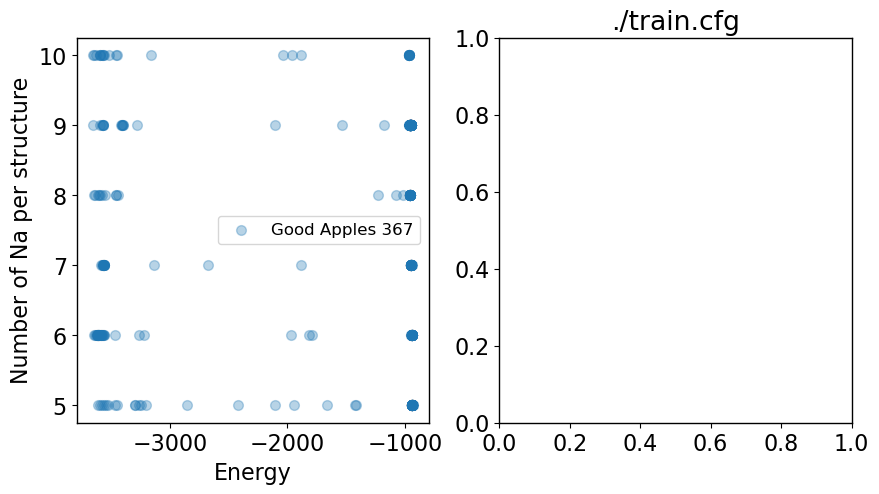

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))

#ax1.scatter(E_DFT,Na_count,alpha=0.32)
ax1.scatter(E_DFT[good_apple_ls],Na_count[good_apple_ls],alpha=0.32, label=f'Good Apples {len(good_apple_ls)}')
#ax1.scatter(E_DFT[bad_apple_ls],Na_count[bad_apple_ls],alpha=0.32, label=f'Bad Apples {len(bad_apple_ls)}')
ax1.set_xlabel('Energy')
ax1.set_ylabel('Number of Na per structure')
ax1.legend()
#ax1.set_xlim(-4000,0)

#ax2.scatter(E_DFT[bad_apple_ls],Na_count[bad_apple_ls],alpha=0.32)
#ax2.set_xlabel('Energy')
#ax2.set_ylabel('Number of Na per structure')

plt.title(filename)

Text(0.5, 1.0, './train.cfg')

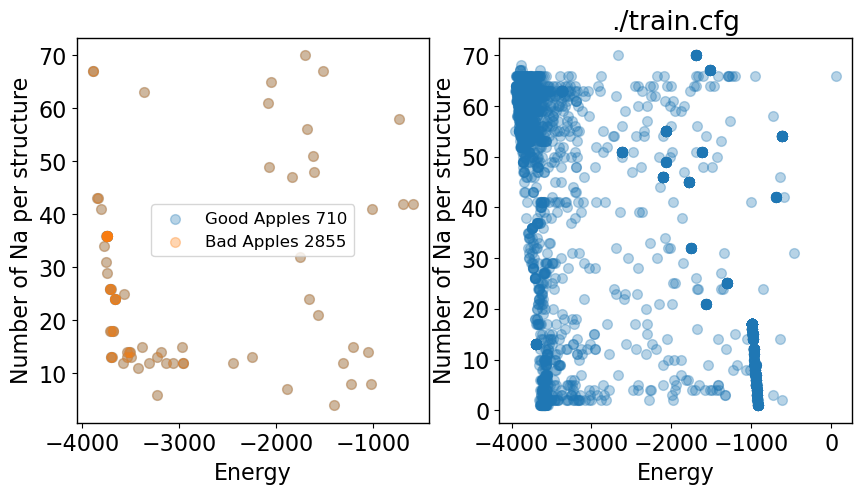

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))

#ax1.scatter(E_DFT,Na_count,alpha=0.32)
ax1.scatter(E_DFT[-76:],Na_count[-76:],alpha=0.32, label=f'Good Apples {len(good_apple_ls)}')
ax1.scatter(E_DFT[-76:],Na_count[-76:],alpha=0.32, label=f'Bad Apples {len(bad_apple_ls)}')
ax1.set_xlabel('Energy')
ax1.set_ylabel('Number of Na per structure')
ax1.legend()
#ax1.set_xlim(-4000,0)

ax2.scatter(E_DFT[bad_apple_ls],Na_count[bad_apple_ls],alpha=0.32)
ax2.set_xlabel('Energy')
ax2.set_ylabel('Number of Na per structure')

plt.title(filename)

Text(0.5, 1.0, './train.cfg')

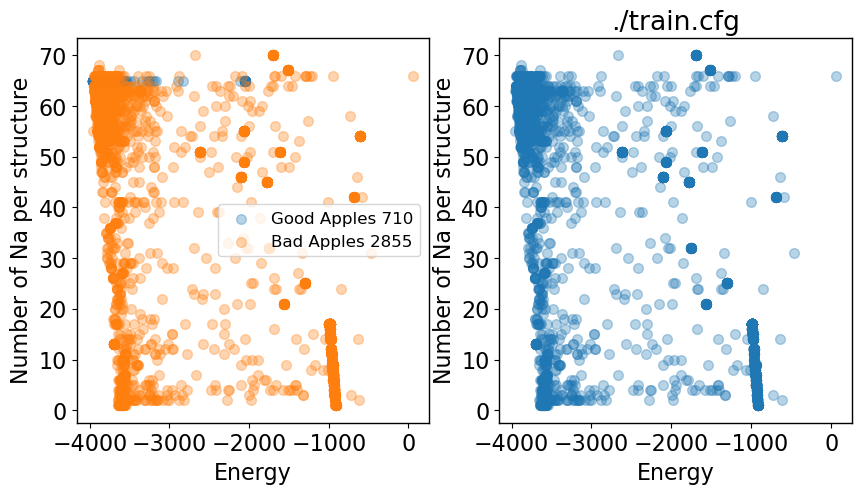

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))

#ax1.scatter(E_DFT,Na_count,alpha=0.32)
ax1.scatter(E_DFT[good_apple_ls],Na_count[good_apple_ls],alpha=0.32, label=f'Good Apples {len(good_apple_ls)}')
ax1.scatter(E_DFT[bad_apple_ls],Na_count[bad_apple_ls],alpha=0.32, label=f'Bad Apples {len(bad_apple_ls)}')
ax1.set_xlabel('Energy')
ax1.set_ylabel('Number of Na per structure')
ax1.legend()
#ax1.set_xlim(-4000,0)

ax2.scatter(E_DFT[bad_apple_ls],Na_count[bad_apple_ls],alpha=0.32)
ax2.set_xlabel('Energy')
ax2.set_ylabel('Number of Na per structure')

plt.title(filename)

In [61]:
E_DFT[good_apple_ls].shape, Na_count[good_apple_ls].shape, supercell.shape

((70,), (70,), (70, 3, 3))

In [48]:
good_apple_ls

[0,
 1,
 2,
 3,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 30,
 32,
 34,
 35,
 36,
 37,
 38,
 41,
 42,
 43,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 66,
 67,
 68,
 69,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 108,
 109,
 110,
 111,
 112,
 113,
 116,
 117,
 118,
 119,
 120,
 121,
 122,
 123,
 124,
 125,
 126,
 127,
 128,
 129,
 130,
 131,
 132,
 133]

In [15]:
E = E_DFT[good_apple_ls]
S = S_DFT[good_apple_ls]
F_DFT = np.array(F_DFT, dtype=object)
F = F_DFT[good_apple_ls]
supercell = supercell[good_apple_ls]

In [50]:
E = E_DFT[-76:]
S = S_DFT[-76:]
F_DFT = np.array(F_DFT, dtype=object)
F = F_DFT[-76:]
supercell = supercell[-76:]

In [18]:
condition_1 = (atom_count > 400) & (E_DFT < -3000)
condition_2 = atom_count < 200
reasonable_indices_1 = np.where(condition_1)
reasonable_indices_2 = np.where(condition_2)
reasonable_indices = np.concatenate((reasonable_indices_1[0],reasonable_indices_2[0]))

In [16]:
def write_cfg(E, supercell, F, S, output_file):
    with open(output_file, 'w') as file:
        for cfg_num in range(E.shape[0]):
            file.write("BEGIN_CFG\n")
            file.write(" Size\n")
            file.write(f"    {F[cfg_num].shape[0]}\n")
            file.write(" Supercell\n") 
            for row in supercell[cfg_num]:
                # Format each element in the row to scientific notation with 17 decimals
                formatted_row = " ".join([f"{elem}" for elem in row])
                file.write(formatted_row + "\n")
            file.write(" AtomData:  id type       cartes_x      cartes_y      cartes_z           fx          fy          fz\n")
    
            for atom in F[cfg_num]:
                atom_id = int(atom[0])
                atom_type = int(atom[1])
                x, y, z = map(float, atom[2:5])
                fx, fy, fz = map(float, atom[5:])
                file.write(f"    {atom_id}    {atom_type}    {x:.6f}    {y:.6f}    {z:.6f}    {fx:.6f}    {fy:.6f}    {fz:.6f}\n")

            file.write(" Energy\n")
            file.write(f"    {E[cfg_num]}\n")
            file.write(" PlusStress:  xx          yy          zz          yz          xz          xy\n")
            stress = " ".join([f"{elem}" for elem in S[cfg_num]])
            file.write(f"    {stress}\n")
            file.write("END_CFG\n")
            file.write("\n")

In [17]:
write_cfg(E, supercell, F, S, './hydration/boost.cfg')

In [23]:
points = np.transpose(np.array((Na_count_train,E_act/atom_count)))
points.shape

ValueError: operands could not be broadcast together with shapes (611,) (2354,) 

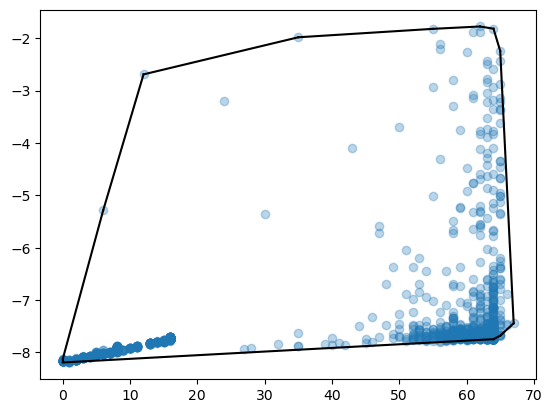

In [99]:
import numpy as np
from scipy.spatial import ConvexHull
import matplotlib.pyplot as plt
points = np.transpose(np.array((Na_count_train,E_act/atom_count)))
points.shape
# Compute the convex hull
hull = ConvexHull(points)

# Plot the points and the convex hull
plt.plot(points[:, 0], points[:, 1], 'o', alpha=0.3)  # Plot points
for simplex in hull.simplices:
    plt.plot(points[simplex, 0], points[simplex, 1], 'k-')  # Draw edges of the hull

plt.show()


In [101]:
import os
import re
import numpy as np
import pandas as pd

def load_multi_section_cfg(filename):
    energies = []
    supercell_list = []
    atom_data_list = []
    stress_data_list = []
    grade_data_list = []
    
    try:
        with open(filename, 'r') as file:
            content = file.read()
            
            # Split the content into sections
            cfg_sections = content.split('BEGIN_CFG')[1:]  # Skip the first empty split
            
            for section in cfg_sections:
                lines = section.strip().split('\n')
                
                # Extract Size
                size = int(next(line.strip() for line in lines if line.strip().isdigit()))

                # Extract Supercell
                supercell_start = next(i for i, line in enumerate(lines) if line.strip().startswith('Supercell'))
                supercell = np.array([list(map(float, line.split()[:])) for line in lines[supercell_start+1:supercell_start+3+1]])
                supercell_list.append(supercell)
                
                # Extract AtomData
                atom_data_start = next(i for i, line in enumerate(lines) if line.strip().startswith('AtomData:'))
                atom_data = np.array([list(map(float, line.split()[:])) for line in lines[atom_data_start+1:atom_data_start+size+1]])
                atom_data_list.append(atom_data)
                
                # Extract Energy
                energy_line_index = next(i for i, line in enumerate(lines) if line.strip().startswith('Energy'))
                energy = float(lines[energy_line_index+1].split()[0])
                energies.append(energy)
                
                # Extract PlusStress
                stress_line = next(line for line in lines if line.strip().startswith('PlusStress:'))
                stress = np.array(list(map(float, lines[lines.index(stress_line) + 1].split())))
                stress_data_list.append(stress)
        
        return np.array(energies), np.array(supercell_list), atom_data_list, np.array(stress_data_list)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")
        return None, None, None

filename = './vasp.cfg'
E_DFT, supercell, F_DFT, S_DFT = load_multi_section_cfg(filename)
active_set = np.where(E_DFT < -3000)

E = E_DFT[active_set[0]]
S = S_DFT[active_set[0]]
F_DFT = np.array(F_DFT, dtype=object)
F = F_DFT[active_set[0]]
supercell = supercell[active_set[0]]

def write_cfg(E, supercell, F, S, output_file):
    with open(output_file, 'w') as file:
        for cfg_num in range(E.shape[0]):
            file.write("BEGIN_CFG\n")
            file.write(" Size\n")
            file.write(f"    {F[cfg_num].shape[0]}\n")
            file.write(" Supercell\n") 
            for row in supercell[cfg_num]:
                # Format each element in the row to scientific notation with 17 decimals
                formatted_row = " ".join([f"{elem}" for elem in row])
                file.write(formatted_row + "\n")
            file.write(" AtomData:  id type       cartes_x      cartes_y      cartes_z           fx          fy          fz\n")
    
            for atom in F[cfg_num]:
                atom_id = int(atom[0])
                atom_type = int(atom[1])
                x, y, z = map(float, atom[2:5])
                fx, fy, fz = map(float, atom[5:])
                file.write(f"    {atom_id}    {atom_type}    {x:.6f}    {y:.6f}    {z:.6f}    {fx:.6f}    {fy:.6f}    {fz:.6f}\n")

            file.write(" Energy\n")
            file.write(f"    {E[cfg_num]}\n")
            file.write(" PlusStress:  xx          yy          zz          yz          xz          xy\n")
            stress = " ".join([f"{elem}" for elem in S[cfg_num]])
            file.write(f"    {stress}\n")
            file.write("END_CFG\n")
            file.write("\n")

write_cfg(E, supercell, F, S, './cleaned_vasp.cfg')

In [99]:
E

array([-3885.61988787, -3926.50502505, -3789.49782937])

## Prepare ACE input

In [53]:
from ase import Atoms
filename = './train.cfg'
E_DFT, supercell, F_DFT, S_DFT = load_multi_section_cfg_no_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)
#at1 = Atoms(symbols=symbls1, positions=pos1, cell=lattice1, pbc=True)

In [54]:
F_DFT.shape[0]

2007

In [55]:
# symbols
mapping = {0: 'C', 1: 'Mn', 2: 'Fe', 3: 'N', 4: 'Na'}

symbol_ls = []
# Replace numbers with symbols
for i in range(F_DFT.shape[0]):
    symbol = [mapping[int(num)] for num in F_DFT[i][:,1]]
    symbol_ls.append(symbol)

In [56]:
symbol_ls[-1]

['C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C',
 'C'

In [63]:
# position
F_DFT[i][:10,2:5]

array([[ 7.2434 ,  7.36594, 13.48534],
       [ 6.3875 , 11.16514, 11.05594],
       [11.2983 , 10.19314, 13.68388],
       [ 9.5182 ,  8.51994,  9.73006],
       [13.7131 , 11.09774,  9.74256],
       [14.67386,  7.55054, 12.48051],
       [ 6.8974 , 11.00884, 18.6068 ],
       [ 9.4179 , 11.78428, 14.63065],
       [12.5489 ,  8.11474, 18.63741],
       [10.3043 ,  7.99094, 17.31657]])

In [64]:
# force
force_ls = []
for i in range(F_DFT.shape[0]):
    force_ls.append(F_DFT[i][:,5:])

In [65]:
# Lattice
supercell[0]

array([[19.66579 , -1.120916, -0.198411],
       [ 1.421209,  9.61417 , -0.41994 ],
       [ 1.50835 ,  1.294224,  9.727623]])

In [66]:
# Energy
E_DFT

array([-992.252393  , -991.746629  , -990.812064  , ..., -869.70813636,
       -253.99960447, -210.54352286])

In [67]:
# Energy correct
## for big structure,
E_C = -9.2203
E_Fe = -8.4693
E_Mn = -9.1617
E_N =  -9.60
E_Na = -1.3097
E_big = 192*E_C + 32*E_Mn + 32*E_Fe + 192*E_N + 64*E_Na
E_big

-4261.5104

In [68]:
structure_ls = []

for i in range(F_DFT.shape[0]):
    structure_ls.append(Atoms(symbols=symbol_ls[i], positions=F_DFT[i][:,2:5], cell=supercell[0], pbc=True))

In [69]:
data = {'energy': E_DFT, 
        'forces': force_ls, 
        'ase_atoms': structure_ls, 
        'energy_corrected': E_DFT}

In [70]:
# create a DataFrame
df = pd.DataFrame(data)
# and save it 
df.to_pickle('./ACE/my_data.pckl.gzip', compression='gzip', protocol=4)

# To load the data
#df = pd.read_pickle("../data/exmpl_df.pckl.gzip", compression="gzip", protocol=4)

In [71]:
df

,energy,forces,ase_atoms,energy_corrected
0,-992.252393,"[[1.229719, 0.335897, -0.50103], [3.701312, 0....","(Atom('C', [2.983072, 5.867585, 4.283053], ind...",-992.252393
1,-991.746629,"[[-1.983072, -0.522524, 0.813984], [-4.019485,...","(Atom('C', [1.615487, 5.181329, 4.584679], ind...",-991.746629
2,-990.812064,"[[2.674847, 0.552258, -0.043174], [-2.742974, ...","(Atom('C', [21.107529, 4.732678, 4.161717], in...",-990.812064
3,-991.020806,"[[-6.519257, -1.308731, 1.087008], [-1.151485,...","(Atom('C', [2.795734, 5.856559, 4.470947], ind...",-991.020806
4,-991.324275,"[[0.711016, 0.923285, -0.530961], [-1.479108, ...","(Atom('C', [1.958819, 5.155596, 4.61301], inde...",-991.324275
...,...,...,...,...
1983,-3742.709541,"[[-0.155106, 3.651901, 0.612713], [-0.617603, ...","(Atom('C', [6.87702, 8.49161, 10.27924], index...",-3742.709541
1984,-3750.523947,"[[1.601203, 0.492526, -0.338806], [0.266538, 1...","(Atom('C', [19.0662, 17.75121, 16.79913], inde...",-3750.523947
1985,-869.708136,"[[1.975716, 0.912367, -0.551228], [0.83682, -0...","(Atom('C', [9.39443, 14.90077, 14.69181], inde...",-869.708136
1986,-253.999604,"[[-1.825586, -0.818766, 0.460021], [-0.65006, ...","(Atom('C', [21.33591, 19.08261, 13.4601], inde...",-253.999604


In [73]:
from ase.visualize import view
import nglview as nv
view = nv.show_ase(structure_ls[-20])
view

NGLWidget()

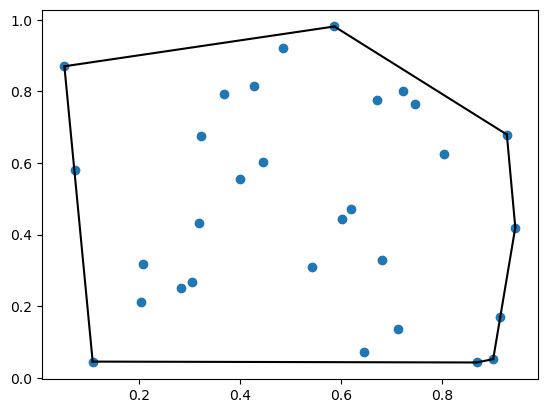

In [78]:
import numpy as np
from scipy.spatial import ConvexHull
import matplotlib.pyplot as plt

# Generate some random 2D points
points = np.random.rand(30, 2)

# Compute the convex hull
hull = ConvexHull(points)

# Plot the points and the convex hull
plt.plot(points[:, 0], points[:, 1], 'o')  # Plot points
for simplex in hull.simplices:
    plt.plot(points[simplex, 0], points[simplex, 1], 'k-')  # Draw edges of the hull

plt.show()


In [10]:
def insert_to_line_6(file_path, text_to_insert):
    # Read the file contents
    with open(file_path, 'r') as file:
        lines = file.readlines()
    
    # Insert the text into the 6th line (index 5 since it's 0-based indexing)
    lines.insert(5, text_to_insert + '\n')
    
    # Write the modified content back to the file
    with open(file_path, 'w') as file:
        file.writelines(lines)

In [14]:
path = './strange'
files = os.listdir(path)

for i in files:
        ###### RDF ######
    r = pdf[:,1]
    fig = plt.figure(figsize=(8,5))
    for i in range(2, pdf.shape[1],2):
        j = int(i/2)
        plt.plot(r, pdf[:,i], label = name[j-1], color = colors[j-1])
        plt.text(pdf[:,1][pdf[:,i].argmax()], 
                 pdf[:,i].max(), 
                 f'{pdf[:,1][pdf[:,i].argmax()]}',
                 color = colors[j-1])
    plt.legend()
    plt.xlabel('r (A)')
    plt.xlim(0,5)
    plt.ylabel('G(r)')
    plt.grid()
    plt.title(iteration+ f' RDF_{poscar_numbers[pos_num]}'+f' n_Na = {na_count}')
    plt.savefig(path + iteration + f'/RDF_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

    ###### Bond angles #####
    from collections import Counter
    # Extract species (element types) from the sites
    species = [site.species_string for site in struct.sites]
    
    # Count the occurrences of each species
    species_counts = Counter(species)
    counts_list = []
    
    # Print the number of atoms of each type
    for element, count in species_counts.items():
        #print(f"Element: {element}, Count: {count}")
        counts_list.append(count)
        
    #1. find the coordiate of all Mn atoms
    coordinates = []
    for site in struct.sites:
        x, y, z = site.coords  # Extracting the coordinates
        coordinates.append((x, y, z))  # Append to the list 
    C_coor = np.array(coordinates[:counts_list[0]])
    Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
    Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
    N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:])

    #2. find the 6 closest atoms to each Mn which should be N
    distance_threshold = 3.0
    # Initialize a list to store the results
    n_within_distance = []
    # Calculate distances
    for mn in Mn_coor:
        distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_n = N_coor[distances < distance_threshold]
        n_within_distance.append(close_n)
    n_within_distance = np.array(n_within_distance)

    #3. find the closet atom to those N which should be C
    distance_threshold = 2.5
    # Initialize a list to store the results
    c_within_distance = []
    # Calculate distances
    for i in range(n_within_distance.shape[0]):
        for j in range(n_within_distance[i].shape[0]):
            n = n_within_distance[i][j]
            distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
            # Find N coordinates within the distance threshold
            close_c = C_coor[distances < distance_threshold]
            c_within_distance.append(close_c)

    #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
    Mn_N_C_angles = []
    c_index = 0
    for i in range(n_within_distance.shape[0]):
        for j in range(n_within_distance[i].shape[0]):
            Mn = Mn_coor[i]
            N = n_within_distance[i][j]
            if c_index < len(c_within_distance):
                C_n = c_within_distance[c_index]
            else:
                print(f"Warning: c_index {c_index} out of bounds, skipping...")
                continue  # Skip to the next iteration if out of bounds
            try:
                # Calculate the bond angle and append to the list
                angle = calculate_bond_angle(Mn, N, C_n)
                Mn_N_C_angles.append(angle)
            except Exception as e:
                # Handle any exceptions and continue the loop
                print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
            c_index += 1  # Increment c_index regardless of success or failure
    
    #2. find the 6 closest atoms to each Mn which should be N
    distance_threshold = 3.0
    
    # Initialize a list to store the results
    c_within_distance = []
    
    # Calculate distances
    for fe in Fe_coor:
        distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
        # Find C coordinates within the distance threshold
        close_c = C_coor[distances < distance_threshold]
        c_within_distance.append(close_c)
    
    c_within_distance = np.array(c_within_distance)

    #3. find the closet atom to those N which should be C
    
    distance_threshold = 2.5
    
    # Initialize a list to store the results
    n_within_distance = []
    
    # Calculate distances
    for i in range(c_within_distance.shape[0]):
        for j in range(c_within_distance[i].shape[0]):
            c = c_within_distance[i][j]
            distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
            # Find N coordinates within the distance threshold
            close_n = N_coor[distances < distance_threshold]
            n_within_distance.append(close_n)
    
    n_within_distance = np.array(n_within_distance)

    #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
    Fe_C_N_angles = []
    n_index = 0
    for i in range(c_within_distance.shape[0]):
        for j in range(c_within_distance[i].shape[0]):
            Fe = Fe_coor[i]
            C = c_within_distance[i][j]
            
            # Ensure c_index is within bounds
            if n_index < len(n_within_distance):
                N_c = n_within_distance[n_index]
            else:
                print(f"Warning: c_index {n_index} out of bounds, skipping...")
                continue  # Skip to the next iteration if out of bounds
            try:
                # Calculate the bond angle and append to the list
                angle = calculate_bond_angle(Fe,C,N_c)
                Fe_C_N_angles.append(angle)
            except Exception as e:
                # Handle any exceptions and continue the loop
                print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
            
            n_index += 1  # Increment c_index regardless of success or failure

    fig = plt.figure(figsize=(6,5))
    
    bin_edges = range(90,180,1)  # bins from -10 to 20
    i=0
    # Plotting the first histogram
    counts, edges, bars = plt.hist([Mn_N_C_angles, Fe_C_N_angles], bins = bin_edges,
                                   alpha=0.7, color=['red','blue'], 
                                    label = ['Mn-N-C bond angles', 'Fe_C_N bond angles'])
    plt.text(92,8,f'Mn-N-C angles = {round(sum(Mn_N_C_angles) / len(Mn_N_C_angles),3)}\nFe_C_N angles = {round(sum(Fe_C_N_angles) / len(Fe_C_N_angles),3)}')
    plt.xlabel('Bond Angles')
    plt.ylabel('Count')
    plt.legend()
    plt.title(iteration+ f' bond angle_{poscar_numbers[pos_num]}'+f' n_Na = {na_count}')
    plt.savefig(path + iteration + f'/bond angle_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

    fig = plt.figure(figsize=(6,5))

    bin_edges = range(3,9,1)  # bins from -10 to 20
    i=0
    # Plotting the first histogram
    counts, edges, bars = plt.hist([FeC_coor[:,2],MnN_coor[:,2],NaN_coor[:,2]], bins = bin_edges,
                                   alpha=0.7, color=['red','blue','green'], 
                                   edgecolor='black', label = ['FeC_coor','MnN_coor','NaN_coor'])
    plt.text(3,20,f'Fe-C coor. = {FeC_coor[:,2].mean()}\nMn-N coor. = {MnN_coor[:,2].mean()}\nNa-N coor. = {NaN_coor[:,2].mean()}')
    plt.title(f'Atom count'+f' n_Na = {na_count}')
    plt.xlabel('Coordination number')
    plt.ylabel('Count')
    #plt.legend(frameon=False)
    
    plt.savefig(path + iteration + f'/coordination_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')


In [12]:
files

['strange_poscar11',
 'strange_poscar45',
 'strange_poscar30',
 'strange_poscar6',
 'strange_poscar39',
 'strange_poscar7',
 'strange_poscar42',
 'strange_poscar64',
 'strange_poscar1',
 'strange_poscar23',
 'strange_poscar49',
 'strange_poscar5',
 'strange_poscar66',
 'strange_poscar16',
 'strange_poscar47',
 'strange_poscar12',
 'strange_poscar62',
 'strange_poscar58',
 'strange_poscar50',
 'strange_poscar54',
 'strange_poscar37',
 'strange_poscar65',
 'strange_poscar28',
 'strange_poscar46',
 'strange_poscar18',
 'strange_poscar41',
 'strange_poscar0',
 'strange_poscar8',
 'strange_poscar31',
 'strange_poscar60',
 'strange_poscar27',
 'strange_poscar43',
 'strange_poscar36',
 'strange_poscar67',
 'strange_poscar38',
 'strange_poscar19',
 'strange_poscar61',
 'strange_poscar59',
 'strange_poscar35',
 'strange_poscar4',
 'strange_poscar14',
 'strange_poscar57',
 'strange_poscar40',
 'strange_poscar22',
 'strange_poscar15',
 'strange_poscar55',
 'strange_poscar9',
 'strange_poscar63',
